<a href="https://colab.research.google.com/github/farahdinaariff/Data-Science-Project/blob/main/TropicalPV_Probabilistic_Solar_Forecasting_v1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TropicalPV — Probabilistic Solar Irradiance Forecasting Under Tropical Climate Uncertainty

**MSc Data Science 7FTC2001 — Farah Dina Esa Mahmud Ariff**

Deterministic (LSTM, GRU) vs. uncertainty-quantifying (MC-Dropout LSTM, Quantile-Regression GRU)
deep learning for short-horizon solar irradiance forecasting across a four-site climate gradient.

---
## How this notebook is built (read this first)

This is a **single self-contained notebook**. There are no `import` statements from local `.py`
files, no helper scripts, no `%run`, no cloned repos. Every function and class used lives in the
cells below.

Three structural properties make it finish where the previous version could not:

1. **Bounded memory.** No raw file is ever fully materialised in RAM. The 1-second DKASC Darwin
   files are aggregated to hourly *while streaming*, in fixed-size chunks, reading only the
   columns actually needed. Peak RAM is a function of `CHUNK_ROWS`, not of file size.
2. **Checkpoint-and-resume.** Every expensive stage writes a small artifact to Drive and reloads
   it if present. A runtime restart costs seconds, not the whole run. No cell depends on a
   variable that only exists because some earlier cell happened to still be in memory.
3. **Degrade, never crash.** A missing or malformed file is recorded in a load ledger and the
   site is skipped. Downstream stages iterate over whatever loaded successfully.

Run order: top to bottom, once. `Runtime > Run all` is expected to work.

## PART 0 — Runtime setup and configuration

One configuration object. Change things here, nowhere else.

`MODE = "SMOKE"` runs the identical code path end-to-end with capped epochs and capped rows —
use it once to confirm the notebook completes in your environment (~5–8 min). `MODE = "FULL"`
is the real run. **The code path is the same**; only sizes differ. This is not a "test version".

In [ ]:
import os, sys, re, gc, json, math, time, warnings, textwrap
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter

warnings.filterwarnings("ignore")
pd.set_option("display.width", 190)
pd.set_option("display.max_columns", 60)
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "font.size": 9,
    "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False,
    "axes.spines.right": False, "figure.autolayout": True,
})

IN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")


class CFG:
    # ---- environment -------------------------------------------------------
    MODE = "FULL"                 # "SMOKE" | "FULL"
    SEED = 42

    # Root that CONTAINS the five Data-* folders. Adjust to match your Drive.
    DRIVE_ROOT = "/content/drive/MyDrive/DSP_Data"
    ARTIFACT_DIRNAME = "_tropicalpv_artifacts"

    # ---- ingestion ---------------------------------------------------------
    CHUNK_ROWS = 400_000          # streaming chunk size; controls peak RAM
    TARGET_FREQ = "h"             # modelling resolution

    # ---- physics / QC ------------------------------------------------------
    GHI_MAX = 1400.0              # W/m^2 physical ceiling
    NEG_TOLERANCE = -10.0         # night-time sensor offset tolerated then zeroed
    KT_MAX = 1.30                 # clear-sky index ceiling (cloud enhancement)
    DAYLIGHT_CS_MIN = 20.0        # W/m^2 clear-sky threshold defining "daylight"
    MAX_INTERP_GAP_H = 3          # gaps <= this are interpolated; longer are left NaN

    # ---- supervised problem -------------------------------------------------
    LOOKBACK = 24                 # hours of history
    HORIZON = 1                   # hours ahead (t+1)
    RAMP_KT_THRESHOLD = 0.35      # |d(kt)/dt| defining a ramp event
    TRAIN_FRAC, VAL_FRAC = 0.70, 0.15   # chronological, never shuffled

    # ---- models -------------------------------------------------------------
    UNITS = 64
    DROPOUT = 0.20
    EPOCHS = 60
    BATCH = 128
    PATIENCE = 8
    MC_PASSES = 50
    QUANTILES = [0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95]
    PI_LOW, PI_HIGH = 0.10, 0.90  # headline 80% prediction interval

    # ---- housekeeping --------------------------------------------------------
    FORCE_REBUILD = False         # True = ignore existing checkpoints
    MAX_ROWS_PER_FILE = None      # set by SMOKE


if CFG.MODE == "SMOKE":
    CFG.EPOCHS, CFG.PATIENCE, CFG.MC_PASSES = 3, 2, 10
    CFG.MAX_ROWS_PER_FILE = 300_000

np.random.seed(CFG.SEED)

# ---- Drive mount (silently skipped when not on Colab) -----------------------
if IN_COLAB:
    try:
        from google.colab import drive
        if not os.path.ismount("/content/drive"):
            drive.mount("/content/drive")
    except Exception as e:                                   # pragma: no cover
        print(f"[warn] Drive mount skipped: {e}")

def find_data_root(declared: str) -> Path:
    """Locate the folder that CONTAINS the Data-* directories.

    A wrong DRIVE_ROOT is the single most common first-run failure, and it
    surfaces later as a confusing 'no site loaded' error. This resolves it up
    front by looking for the DKASC folder under the usual Drive locations.
    """
    p = Path(declared)
    if (p / "Data-DKASC Darwin").exists():
        return p
    roots = [p, Path("/content/drive/MyDrive"), Path("/content/drive/My Drive"),
             Path("/content"), Path.cwd()]
    for r in roots:
        if not r.exists():
            continue
        if (r / "Data-DKASC Darwin").exists():
            return r
        try:
            for cand in sorted(r.rglob("Data-DKASC Darwin"))[:1]:
                log(f"data root auto-detected: {cand.parent}", "warn")
                return cand.parent
        except (PermissionError, OSError):
            continue
    return p


ROOT = Path(CFG.DRIVE_ROOT)
ART = ROOT / CFG.ARTIFACT_DIRNAME
ART.mkdir(parents=True, exist_ok=True)
FIGDIR = ART / "figures"
FIGDIR.mkdir(exist_ok=True)

print(f"Mode        : {CFG.MODE}")
print(f"Data root   : {ROOT}   exists={ROOT.exists()}")
print(f"Artifacts   : {ART}")

Mounted at /content/drive
Mode        : FULL
Data root   : /content/drive/MyDrive/DSP_Data   exists=True
Artifacts   : /content/drive/MyDrive/DSP_Data/_tropicalpv_artifacts


### 0.1 Utilities — memory reporting, checkpointing, logging

`checkpoint()` is the mechanism that removes the "42 stateful phases" failure mode. Any stage
wrapped in it becomes idempotent and restart-safe.

In [ ]:
def mem_mb() -> float:
    """Resident set size in MB. Works with or without psutil."""
    try:
        import psutil
        return psutil.Process(os.getpid()).memory_info().rss / 1e6
    except Exception:
        try:
            with open("/proc/self/statm") as f:
                return int(f.read().split()[1]) * os.sysconf("SC_PAGE_SIZE") / 1e6
        except Exception:
            return float("nan")


_T0 = time.time()


def log(msg: str, level: str = "info") -> None:
    tag = {"info": "   ", "ok": " ok", "warn": "  !", "err": " XX", "step": "==>"}[level]
    print(f"[{time.time()-_T0:7.1f}s |{mem_mb():7.0f}MB] {tag} {msg}")


def _pq_ok() -> bool:
    try:
        import pyarrow  # noqa: F401
        return True
    except Exception:
        return False


HAS_PARQUET = _pq_ok()


def save_table(df: pd.DataFrame, name: str) -> Path:
    """Persist a dataframe artifact. Parquet when available, else compressed CSV."""
    if HAS_PARQUET:
        p = ART / f"{name}.parquet"
        df.to_parquet(p, index=False)
    else:
        p = ART / f"{name}.csv.gz"
        df.to_csv(p, index=False, compression="gzip")
    return p


def load_table(name: str):
    for p, rd in ((ART / f"{name}.parquet", pd.read_parquet),
                  (ART / f"{name}.csv.gz", pd.read_csv)):
        if p.exists():
            df = rd(p)
            for c in df.columns:
                if c in ("ts",) or c.endswith("_ts"):
                    df[c] = pd.to_datetime(df[c])
            return df
    return None


def checkpoint(name: str, builder, force: bool = None):
    """Return artifact `name`, building (and persisting) it only if absent."""
    force = CFG.FORCE_REBUILD if force is None else force
    if not force:
        cached = load_table(name)
        if cached is not None:
            log(f"checkpoint hit  '{name}'  ({len(cached):,} rows)", "ok")
            return cached
    log(f"checkpoint build '{name}' ...", "step")
    df = builder()
    save_table(df, name)
    log(f"checkpoint saved '{name}'  ({len(df):,} rows)", "ok")
    return df


def savefig(fig, name: str):
    fig.savefig(FIGDIR / f"{name}.png", bbox_inches="tight")

## PART 1 — Data audit: what stays in the pipeline, what is removed, and why

The previous pipeline attempted to ingest every file present in the Drive folder. That is the
root cause of most of its instability, so the rebuild starts from an explicit, defensible
manifest rather than from a directory listing.

The decision rule applied to every file is a single question drawn from the proposal:

> *Does this file supply either (a) the target variable — solar irradiance, or measured PV power
> at a site where co-located irradiance also exists — or (b) an hourly-resolvable meteorological
> predictor time-aligned to that target?*

A file that answers "no" cannot contribute to the stated research question, no matter how large
or how interesting it is. Every drop below is justified on that rule, not on convenience.

In [ ]:
# (folder, filename regex, decision, role, reason)
MANIFEST = [
    # ---------------------------------------------------------------- KEEP ---
    ("Data-DKASC Darwin", r"fsm1m_7127.*darwin.*irradiancedata_1sec_(2021|2022|2023)",
     "KEEP", "DARWIN:irradiance",
     "Primary target. Confirmed Darwin-sourced irradiance (reference cells MB0/MB1). "
     "Streamed to hourly; never loaded whole."),

    ("Data-DKASC Darwin", r"fsm1m_7111.*alice-springs.*irradiancedata",
     "KEEP", "ALICE:irradiance",
     "Co-located irradiance at the arid validation site. Required to quantify the "
     "irradiance-as-PV-proxy delta (Objective 1, secondary)."),

    ("Data-DKASC Darwin", r"fsm1m_7111.*alice-springs.*metdata",
     "KEEP", "ALICE:met",
     "Air temperature / RH / rainfall for Alice. Only source of met predictors at that site."),

    ("Data-DKASC Darwin", r"fsm1m_7111.*alice-springs.*windvectordata",
     "KEEP", "ALICE:wind",
     "Wind speed / direction for Alice. Completes the predictor set to match other sites."),

    ("Data-DKASC Darwin", r"^241-Site_DKA_Totals-PV",
     "KEEP", "ALICE:pv",
     "Measured site PV output (Active_Power) with co-located GHI. This single file is the "
     "entire empirical basis for the proxy-validation objective."),

    ("Data-Nasa Power Singapore", r"^POWER_Point_Hourly_.*_LST",
     "KEEP", "SINGAPORE:all",
     "The only equatorial GHI source in the folder at hourly resolution, and it ships "
     "co-located T2M/RH2M/WS10M plus a clear-sky reference. Carries the entire Singapore arm."),

    ("Data-NSRDB US Soutwest", r"^2526694_26\.06_-80\.33_20\d\d",
     "KEEP", "NSRDB:all",
     "Fourth climate in the gradient. GHI + clear-sky GHI + met, hourly-resolvable."),

    # ---------------------------------------------------------------- DROP ---
    ("Data-DataGovSG", r"^Historical (Air Temperature|Rainfall|Relative Humidity|Wind Direction|Wind Speed) across Singapore",
     "DROP", "-",
     "REDUNDANT + PRIMARY INSTABILITY SOURCE. ~46 GB / 45 files of per-station long-format "
     "readings at ~1-minute cadence, containing no irradiance at all. The equatorial arm needs "
     "GHI plus met on one time axis; NASA POWER already supplies exactly that, hourly and "
     "pre-aligned. Reconstructing an equivalent from these files requires a 45-file spatial "
     "average across a changing station roster — the dominant cause of the RAM exhaustion. "
     "Removing them costs the project no variable it does not already have."),

    ("Data-DataGovSG", r"^WaterTemperatureandWeatherData",
     "DROP", "-",
     "WRONG RESOLUTION. Its 'Solar irradiance / W/m2' column is a MONTHLY mean, and the series "
     "has an Oct–Dec 2024 buoy-refurbishment hole. A t+1-hour forecasting task cannot use a "
     "monthly series; 12 values/year cannot be upsampled to hourly without inventing the "
     "variance the study exists to measure."),

    ("Data-DataGovSG", r"^ElectricityGenerationMonthly",
     "DROP", "-",
     "OFF-OBJECTIVE. Monthly national generation in ~380 wide date-columns. National dispatch "
     "totals are not a solar irradiance predictor. Cite in the report's context section instead."),

    ("Data-DataGovSG", r"^AnnualFuelMix",
     "DROP", "-",
     "OFF-OBJECTIVE. Annual fuel-mix percentages — one row per year. No time-series content."),

    ("Data-DataGovSG", r"^(InstalledCapacityofGridConnected|SolarPVInstallationsbyURA)",
     "DROP", "-",
     "OFF-OBJECTIVE. Annual installed-capacity statistics. Useful as report motivation, "
     "structurally incapable of entering an hourly model."),

    ("Data-Solar Power Generation Data", r"^Plant_[12]_(Generation|Weather_Sensor)_Data",
     "DROP", "-",
     "FALLBACK NOT TRIGGERED. The proposal designates the Kaggle India set as contingency 'if "
     "DKASC fails'. DKASC did not fail — Darwin and Alice both ingest cleanly. Activating an "
     "unneeded fallback adds a fifth schema, a different target (AC power, no co-located "
     "irradiance in the generation file), inverter-level duplicate timestamps across 22 "
     "SOURCE_KEYs, and only 34 days of coverage. Pure downside."),

    ("Data-DKASC Darwin", r"^(239-Site_DKA_Totals-BESS|240-Site_DKA_Totals-Site_Demand|242-Site_DKA_Totals-Grid)",
     "DROP", "-",
     "WRONG SIGNAL. Battery state-of-charge, site load, and grid import/export. Their "
     "Active_Power is confounded by storage dispatch and on-site demand, so it is not a solar "
     "generation signal. 241 (Totals-PV) is the correct and sufficient PV channel."),

    ("Data-DKASC Darwin", r"^(96-Site_DKA-MasterMeter1|101-Site_DKA-WeatherStation)",
     "DROP", "-",
     "REDUNDANT. 96 is a revenue meter (energy accumulator, power factor, THD) whose PV content "
     "duplicates 241; 101 is a weather station whose columns are already embedded in 241. Both "
     "add merge keys and NaN surface for zero new information."),

    ("Data-DKASC Darwin", r"^(3050-Site_Total_Site-PV_Generation|3052-Site_Environment-DG_Weather_Station)",
     "DROP", "-",
     "PROVENANCE CONFLICT. These carry site-level PV and pyranometer channels that your own "
     "August 2026 dataset verification concluded are not attributable to Darwin. Including them "
     "would directly contradict the 'Darwin is irradiance-only' position that the proposal and "
     "PDM plan now rest on. Excluded to keep the written claim and the code consistent."),
]


def run_audit(root: Path) -> pd.DataFrame:
    rows = []
    for folder, pattern, decision, role, reason in MANIFEST:
        d = root / folder
        matched = []
        if d.exists():
            rx = re.compile(pattern, re.I)
            matched = sorted(p for p in d.iterdir()
                             if p.is_file() and rx.search(p.stem))
        size = sum(p.stat().st_size for p in matched) / 1e6
        rows.append({"folder": folder, "pattern": pattern, "decision": decision,
                     "role": role, "n_files": len(matched), "size_mb": round(size, 1),
                     "reason": reason,
                     "_paths": [str(p) for p in matched]})
    return pd.DataFrame(rows)


ROOT = find_data_root(CFG.DRIVE_ROOT)
if str(ROOT) != CFG.DRIVE_ROOT:
    ART = ROOT / CFG.ARTIFACT_DIRNAME
    ART.mkdir(parents=True, exist_ok=True)
    FIGDIR = ART / "figures"
    FIGDIR.mkdir(exist_ok=True)
print(f"Resolved data root: {ROOT}")
if not (ROOT / "Data-DKASC Darwin").exists():
    print("\n  !! 'Data-DKASC Darwin' not found under this root.\n"
          "     Set CFG.DRIVE_ROOT to the folder that CONTAINS your Data-* directories,\n"
          "     then re-run from the top. Everything below will report 0 files until then.\n")

AUDIT = run_audit(ROOT)

kept = AUDIT[AUDIT.decision == "KEEP"]
dropped = AUDIT[AUDIT.decision == "DROP"]

print("=" * 108)
print("DATA AUDIT — FILES ENTERING THE PIPELINE")
print("=" * 108)
for _, r in kept.iterrows():
    print(f"\n  KEEP  {r.role:<22} {r.n_files:>3} file(s)  {r.size_mb:>9,.1f} MB   [{r.folder}]")
    print(textwrap.fill(r.reason, 100, initial_indent="        ", subsequent_indent="        "))

print("\n" + "=" * 108)
print("DATA AUDIT — FILES REMOVED FROM THE PIPELINE")
print("=" * 108)
for _, r in dropped.iterrows():
    print(f"\n  DROP  {r.n_files:>3} file(s)  {r.size_mb:>9,.1f} MB   [{r.folder}]  {r.pattern}")
    print(textwrap.fill(r.reason, 100, initial_indent="        ", subsequent_indent="        "))

print("\n" + "-" * 108)
print(f"  RETAINED : {kept.n_files.sum():>4} files   {kept.size_mb.sum():>10,.1f} MB")
print(f"  REMOVED  : {dropped.n_files.sum():>4} files   {dropped.size_mb.sum():>10,.1f} MB")
print("-" * 108)

save_table(AUDIT.drop(columns=["_paths"]), "audit_manifest")

PATHS = {}
for _, r in kept.iterrows():
    PATHS.setdefault(r.role, []).extend(r._paths)

missing_roles = [r.role for _, r in kept.iterrows() if r.n_files == 0]
if missing_roles:
    log(f"roles with no matching file (their site will be skipped): {missing_roles}", "warn")

Resolved data root: /content/drive/MyDrive
DATA AUDIT — FILES ENTERING THE PIPELINE

  KEEP  DARWIN:irradiance        3 file(s)    3,439.0 MB   [Data-DKASC Darwin]
        Primary target. Confirmed Darwin-sourced irradiance (reference cells MB0/MB1). Streamed to
        hourly; never loaded whole.

  KEEP  ALICE:irradiance         1 file(s)       54.2 MB   [Data-DKASC Darwin]
        Co-located irradiance at the arid validation site. Required to quantify the irradiance-as-
        PV-proxy delta (Objective 1, secondary).

  KEEP  ALICE:met                1 file(s)       36.9 MB   [Data-DKASC Darwin]
        Air temperature / RH / rainfall for Alice. Only source of met predictors at that site.

  KEEP  ALICE:wind               1 file(s)       33.5 MB   [Data-DKASC Darwin]
        Wind speed / direction for Alice. Completes the predictor set to match other sites.

  KEEP  ALICE:pv                 1 file(s)       29.1 MB   [Data-DKASC Darwin]
        Measured site PV output (Active_Power)

## PART 2 — Site registry, solar geometry, clear-sky model

Everything downstream is expressed in one canonical schema. Solar position and clear-sky
irradiance are computed in-notebook (NOAA/Spencer geometry + Haurwitz clear-sky) rather than
taken from `pvlib`, so there is no external dependency and every site is treated identically —
NASA POWER and NSRDB *do* ship their own clear-sky columns, and we keep them only to
cross-validate our own, never to mix conventions between sites.

In [ ]:
SITES = {
    "DARWIN": dict(lat=-12.4256, lon=130.8916, tz=9.5, hemi="S",
                   climate="Tropical savanna (Köppen Aw)",
                   wet_months=[11, 12, 1, 2, 3, 4],
                   season_names=("Dry", "Wet"), role="Primary — tropical target"),
    "ALICE": dict(lat=-23.7615, lon=133.8747, tz=9.5, hemi="S",
                  climate="Hot arid (Köppen BWh)",
                  wet_months=[11, 12, 1, 2, 3],
                  season_names=("Dry", "Wet"), role="Proxy validation — measured PV ground truth"),
    "SINGAPORE": dict(lat=1.3521, lon=103.8198, tz=8.0, hemi="N",
                      climate="Equatorial rainforest (Köppen Af)",
                      wet_months=[11, 12, 1, 2, 3],
                      season_names=("Inter/SW monsoon", "NE monsoon"),
                      role="Cross-climate — equatorial"),
    "NSRDB": dict(lat=26.06, lon=-80.33, tz=-5.0, hemi="N",
                  climate="Humid subtropical / tropical monsoon margin",
                  wet_months=[5, 6, 7, 8, 9, 10],
                  season_names=("Dry", "Wet"), role="Cross-climate — subtropical"),
}

SOLAR_CONSTANT = 1367.0


def solar_geometry(ts_local: pd.DatetimeIndex, lat: float, lon: float, tz: float):
    """Cosine of solar zenith and extraterrestrial horizontal irradiance.

    ts_local is timezone-naive LOCAL standard time; tz is its UTC offset in hours.
    Spencer (1971) declination + equation of time; standard NOAA hour-angle construction.
    """
    utc = pd.DatetimeIndex(ts_local) - pd.Timedelta(hours=tz)
    doy = np.asarray(utc.dayofyear, dtype=float)
    hod = (np.asarray(utc.hour, float)
           + np.asarray(utc.minute, float) / 60.0
           + np.asarray(utc.second, float) / 3600.0)

    g = 2.0 * np.pi * (doy - 1.0 + (hod - 12.0) / 24.0) / 365.0
    eqtime = 229.18 * (0.000075 + 0.001868 * np.cos(g) - 0.032077 * np.sin(g)
                       - 0.014615 * np.cos(2 * g) - 0.040849 * np.sin(2 * g))
    decl = (0.006918 - 0.399912 * np.cos(g) + 0.070257 * np.sin(g)
            - 0.006758 * np.cos(2 * g) + 0.000907 * np.sin(2 * g)
            - 0.002697 * np.cos(3 * g) + 0.001480 * np.sin(3 * g))

    true_solar_min = hod * 60.0 + eqtime + 4.0 * lon
    ha = np.radians(true_solar_min / 4.0 - 180.0)
    la = np.radians(lat)
    cosz = np.sin(la) * np.sin(decl) + np.cos(la) * np.cos(decl) * np.cos(ha)
    cosz = np.clip(cosz, -1.0, 1.0)

    e0 = 1.0 + 0.033 * np.cos(2.0 * np.pi * doy / 365.0)
    ghi_toa = np.clip(SOLAR_CONSTANT * e0 * cosz, 0.0, None)
    return cosz, ghi_toa


def clearsky_haurwitz(cosz: np.ndarray) -> np.ndarray:
    """Haurwitz (1945) clear-sky GHI. Single-parameter, no aerosol inputs required."""
    c = np.where(cosz > 0.0, cosz, np.nan)
    with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
        ghi = 1098.0 * c * np.exp(-0.059 / c)
    return np.nan_to_num(ghi, nan=0.0, posinf=0.0, neginf=0.0)


def attach_solar(df: pd.DataFrame, site: str) -> pd.DataFrame:
    m = SITES[site]
    cosz, toa = solar_geometry(pd.DatetimeIndex(df["ts"]), m["lat"], m["lon"], m["tz"])
    out = df.copy()
    out["cos_zenith"] = cosz
    out["ghi_toa"] = toa
    out["ghi_cs"] = clearsky_haurwitz(cosz)
    out["is_daylight"] = out["ghi_cs"] > CFG.DAYLIGHT_CS_MIN
    return out

### 2.1 Robust readers — header sniffing and unit-aware column normalisation

Four of the five retained sources are hostile to a naive `pd.read_csv`:

| Source | Hazard |
|---|---|
| NASA POWER | 13 lines of prose before the header; `-999` sentinel for missing |
| NSRDB | 2 lines of metadata before the header; lat/lon/timezone live in that metadata |
| DKASC `fsm1m_*` | units embedded in the column name (`Irradiance_MB0 [W/m-2]`); `DD/MM/YYYY` |
| DKASC `241-*` | different timestamp column name *and* a different format entirely |

`sniff_header` locates the real header row by scoring candidate lines against expected tokens,
so none of these offsets are hard-coded. `canon_cols` strips bracketed units and normalises
case/separators, which is what makes one downstream schema possible.

In [ ]:
def sniff_header(path, expect_tokens, max_scan=40) -> int:
    """Index of the row that is actually the CSV header."""
    exp = [t.lower() for t in expect_tokens]
    best, best_hits = 0, 0
    with open(path, "r", errors="replace") as f:
        for i in range(max_scan):
            line = f.readline()
            if not line:
                break
            toks = [t.strip().strip('"').lower() for t in line.split(",")]
            hits = sum(any(e in t for t in toks) for e in exp)
            if hits > best_hits:
                best, best_hits = i, hits
            if hits >= max(2, len(exp) - 1):
                return i
    return best


def canon_cols(cols):
    """`Irradiance_MB0 [W/m-2]` -> `irradiance_mb0`;  `Clearsky GHI` -> `clearsky_ghi`."""
    out = []
    for c in cols:
        c = re.sub(r"\[[^\]]*\]", " ", str(c))          # drop bracketed units
        c = re.sub(r"[^\w]+", "_", c.strip()).strip("_").lower()
        out.append(c)
    return out


def read_csv_smart(path, expect_tokens, usecols=None, nrows=None, chunksize=None):
    """read_csv with the header row detected, columns canonicalised, -999 -> NaN."""
    hdr = sniff_header(path, expect_tokens)
    probe = pd.read_csv(path, skiprows=hdr, nrows=0)
    canon = canon_cols(probe.columns)
    ren = dict(zip(probe.columns, canon))
    keep = None
    if usecols is not None:
        want = set(usecols)
        keep = [orig for orig, cn in ren.items() if cn in want]
        missing = want - {ren[k] for k in keep}
        if missing:
            raise KeyError(f"{Path(path).name}: missing required columns {sorted(missing)}")
    kw = dict(skiprows=hdr, usecols=keep, na_values=[-999, -999.0, "-999", ""],
              low_memory=False)
    if chunksize:
        def gen():
            for ch in pd.read_csv(path, chunksize=chunksize, **kw):
                yield ch.rename(columns=ren)
        return gen()
    return pd.read_csv(path, nrows=nrows, **kw).rename(columns=ren)


def read_nsrdb_metadata(path) -> dict:
    """NSRDB stores latitude/longitude/timezone/state in its 2-row preamble, not the filename."""
    head = pd.read_csv(path, nrows=1)
    row = head.iloc[0]
    get = lambda k, d: (row[k] if k in head.columns and pd.notna(row[k]) else d)
    return {"lat": float(get("Latitude", np.nan)), "lon": float(get("Longitude", np.nan)),
            "tz": float(get("Local Time Zone", get("Time Zone", np.nan))),
            "state": str(get("State", "?")), "city": str(get("City", "?"))}

### 2.2 Streaming hourly aggregation

**This is the fix for the crash.** The Darwin files are ~31.5 M rows/year at 1-second cadence.
Any `pd.read_csv(path)` on them allocates tens of GB and kills a 12.7 GB Colab runtime — which
is why failure began the moment the pipeline stopped inspecting samples and started ingesting
for real.

`stream_to_hourly` never holds more than `CHUNK_ROWS` rows. Each chunk is immediately reduced to
per-hour sums and counts (at most ~112 rows for a 400 k-row chunk of 1 Hz data); only those tiny
reductions accumulate. Peak RAM is constant in file size. Means are formed at the end from
`sum / count`, which is exactly the hourly mean of the raw signal — an average, not a sample,
so no sub-hourly variance is silently discarded through decimation.

In [ ]:
def stream_to_hourly(path, ts_col, ts_format, value_cols, expect_tokens,
                     chunk_rows=None, max_rows=None, dayfirst=True):
    """Reduce an arbitrarily large CSV to hourly means with bounded memory."""
    chunk_rows = chunk_rows or CFG.CHUNK_ROWS
    parts, seen, bad_ts = [], 0, 0

    gen = read_csv_smart(path, expect_tokens,
                         usecols=[ts_col] + value_cols, chunksize=chunk_rows)
    for ch in gen:
        if ts_format:
            ts = pd.to_datetime(ch[ts_col], format=ts_format, errors="coerce")
        else:
            ts = pd.to_datetime(ch[ts_col], errors="coerce")
        if ts.isna().all():
            # fall back once, explicitly day-first, rather than silently mis-parsing
            ts = pd.to_datetime(ch[ts_col], dayfirst=dayfirst, errors="coerce")
        bad_ts += int(ts.isna().sum())
        ch = ch.loc[ts.notna()].copy()
        ch["ts"] = ts[ts.notna()].dt.floor(CFG.TARGET_FREQ)

        num = ch[value_cols].apply(pd.to_numeric, errors="coerce")
        num["ts"] = ch["ts"].to_numpy()
        s = num.groupby("ts", sort=False).sum(min_count=1)
        n = num.groupby("ts", sort=False).count()
        s.columns = [f"{c}__sum" for c in s.columns]
        n.columns = [f"{c}__n" for c in n.columns]
        parts.append(pd.concat([s, n], axis=1))

        seen += len(ch)
        del ch, num, s, n
        if max_rows and seen >= max_rows:
            log(f"    SMOKE cap reached at {seen:,} rows of {Path(path).name}", "warn")
            break

    if not parts:
        raise ValueError(f"{Path(path).name}: no parseable rows")

    agg = pd.concat(parts).groupby(level=0).sum(min_count=1)
    del parts
    gc.collect()

    out = pd.DataFrame(index=agg.index)
    for c in value_cols:
        cnt = agg[f"{c}__n"].replace(0, np.nan)
        out[c] = agg[f"{c}__sum"] / cnt
    out["n_obs"] = agg[[f"{c}__n" for c in value_cols]].max(axis=1)
    out = out.reset_index().rename(columns={"index": "ts"})
    out["ts"] = pd.to_datetime(out["ts"])
    if bad_ts:
        log(f"    {bad_ts:,} unparseable timestamps dropped from {Path(path).name}", "warn")
    return out.sort_values("ts").reset_index(drop=True)

## PART 3 — Ingestion into one canonical schema

### 3.1 Unit registry and naming convention

Every retained source uses a different name and, in three cases, a different unit convention for
the same physical quantity. Rather than sprinkling ad-hoc `rename` calls through the pipeline,
the mapping is declared once, printed, and applied mechanically. Anything not in this registry
does not enter the modelling frame.

In [ ]:
CANON_UNITS = {
    "ghi_wm2": "W/m^2", "ghi_cs_src": "W/m^2", "temp_c": "degC",
    "rh_pct": "%", "wind_ms": "m/s", "pv_kw": "kW",
}

UNIT_REGISTRY = pd.DataFrame([
    # source, source column, source unit, canonical, factor, note
    ("DKASC Darwin",  "Irradiance_MB0 [W/m-2]",  "W·m^-2", "ghi_wm2", 1.0,
     "'[W/m-2]' is W·m^-2, NOT W per m^-2. Read as W/m^2 — no conversion."),
    ("DKASC Darwin",  "UnitTemp_MB0 [deg C]",    "degC",   "temp_c", 1.0,
     "Reference-cell body temperature, not air temperature. Used only as a site covariate."),
    ("DKASC Alice",   "AirTemperatureC_M90",     "degC",   "temp_c", 1.0, "Direct."),
    ("DKASC Alice",   "RelativeHumidity_M90",    "%",      "rh_pct", 1.0, "Clipped to [0,100]."),
    ("DKASC Alice",   "WS_Avg_M51",              "m/s",    "wind_ms", 1.0, "Direct."),
    ("DKASC Alice",   "Active_Power (241)",      "kW",     "pv_kw",  1.0,
     "Site PV real power. Negative values are metering artefacts and are clipped to 0."),
    ("NASA POWER SG", "ALLSKY_SFC_SW_DWN",       "Wh/m^2/h", "ghi_wm2", 1.0,
     "CRITICAL: energy over a 1-hour step is numerically identical to mean power in W/m^2. "
     "Dividing by 1000 or by 3600 here is the classic error — factor is exactly 1."),
    ("NASA POWER SG", "CLRSKY_SFC_SW_DWN",       "Wh/m^2/h", "ghi_cs_src", 1.0,
     "Kept only to cross-check the notebook's own Haurwitz clear-sky curve."),
    ("NASA POWER SG", "T2M / RH2M / WS10M",      "degC / % / m/s", "temp_c / rh_pct / wind_ms", 1.0,
     "Already SI. WS10M is at 10 m; DKASC masts differ in height — noted as a limitation."),
    ("NSRDB",         "GHI",                     "W/m^2",  "ghi_wm2", 1.0, "Direct."),
    ("NSRDB",         "Clearsky GHI",            "W/m^2",  "ghi_cs_src", 1.0, "Cross-check only."),
    ("NSRDB",         "Temperature / Relative Humidity / Wind Speed", "degC / % / m/s",
     "temp_c / rh_pct / wind_ms", 1.0, "Direct; 30-min steps averaged to hourly."),
    ("(all sites)",   "rainfall columns",        "mm (mixed)", "— EXCLUDED —", np.nan,
     "Semantics are irreconcilable: DKASC 'Weather_Daily_Rainfall' and 'RainAccumMM_M90' are "
     "running accumulators, DataGovSG is per-interval, NASA POWER has no precipitation field at "
     "all. A predictor absent at Singapore cannot appear in a zero-shot cross-climate feature "
     "vector, so rainfall is excluded everywhere rather than imputed at one site."),
], columns=["source", "source_column", "source_unit", "canonical", "factor", "note"])

print("UNIT & NAMING REGISTRY")
print("=" * 108)
for _, r in UNIT_REGISTRY.iterrows():
    print(f"\n  {r.source:<15} {str(r.source_column):<42} {r.source_unit:>16}  ->  {r.canonical}")
    print(textwrap.fill(r.note, 100, initial_indent="      ", subsequent_indent="      "))
save_table(UNIT_REGISTRY, "unit_registry")

CANON_COLS = ["ts", "ghi_wm2", "ghi_cs_src", "temp_c", "rh_pct", "wind_ms", "pv_kw", "n_obs"]


def to_canonical(df: pd.DataFrame) -> pd.DataFrame:
    """Guarantee the canonical column set and ordering; absent variables become NaN."""
    out = pd.DataFrame({"ts": pd.to_datetime(df["ts"])})
    for c in CANON_COLS[1:]:
        out[c] = pd.to_numeric(df[c], errors="coerce") if c in df.columns else np.nan
    return out.sort_values("ts").drop_duplicates("ts").reset_index(drop=True)


LOAD_LEDGER = []


def _ledger(site, source, path, rows, note=""):
    LOAD_LEDGER.append({"site": site, "source": source, "file": Path(path).name,
                        "hourly_rows": rows, "note": note})

UNIT & NAMING REGISTRY

  DKASC Darwin    Irradiance_MB0 [W/m-2]                               W·m^-2  ->  ghi_wm2
      '[W/m-2]' is W·m^-2, NOT W per m^-2. Read as W/m^2 — no conversion.

  DKASC Darwin    UnitTemp_MB0 [deg C]                                   degC  ->  temp_c
      Reference-cell body temperature, not air temperature. Used only as a site covariate.

  DKASC Alice     AirTemperatureC_M90                                    degC  ->  temp_c
      Direct.

  DKASC Alice     RelativeHumidity_M90                                      %  ->  rh_pct
      Clipped to [0,100].

  DKASC Alice     WS_Avg_M51                                              m/s  ->  wind_ms
      Direct.

  DKASC Alice     Active_Power (241)                                       kW  ->  pv_kw
      Site PV real power. Negative values are metering artefacts and are clipped to 0.

  NASA POWER SG   ALLSKY_SFC_SW_DWN                                  Wh/m^2/h  ->  ghi_wm2
      CRITICAL: energy over a 1-

### 3.2 Site loaders

One loader per site. Each returns the canonical frame or raises; the caller records the outcome
and continues. A site that fails to load is skipped, never fatal.

In [ ]:
DKASC_IRR_TOKENS = ["timestamp_local", "irradiance", "unittemp"]


def load_darwin():
    """3 annual 1-second files -> hourly. Streamed; two reference cells averaged."""
    frames = []
    for p in PATHS.get("DARWIN:irradiance", []):
        probe = read_csv_smart(p, DKASC_IRR_TOKENS, nrows=5)
        irr = [c for c in probe.columns if c.startswith("irradiance_mb")]
        tmp = [c for c in probe.columns if c.startswith("unittemp_mb")]
        h = stream_to_hourly(p, "timestamp_local", "%d/%m/%Y %H:%M:%S",
                             irr + tmp, DKASC_IRR_TOKENS,
                             max_rows=CFG.MAX_ROWS_PER_FILE)
        # Redundant co-located reference cells -> average is the site irradiance estimate.
        h["ghi_wm2"] = h[irr].mean(axis=1)
        h["temp_c"] = h[tmp].mean(axis=1) if tmp else np.nan
        frames.append(h[["ts", "ghi_wm2", "temp_c", "n_obs"]])
        _ledger("DARWIN", "irradiance(1s)", p, len(h), f"cells={len(irr)}")
    if not frames:
        raise FileNotFoundError("no Darwin irradiance files")
    d = pd.concat(frames, ignore_index=True)
    return to_canonical(d)


def load_alice():
    """Irradiance + met + wind + measured PV, each on its own file and cadence."""
    parts = {}

    for p in PATHS.get("ALICE:irradiance", []):
        probe = read_csv_smart(p, DKASC_IRR_TOKENS, nrows=5)
        irr = [c for c in probe.columns if c.startswith("irradiance_mb")]
        h = stream_to_hourly(p, "timestamp_local", "%d/%m/%Y %H:%M",
                             irr, DKASC_IRR_TOKENS, max_rows=CFG.MAX_ROWS_PER_FILE)
        h["ghi_wm2"] = h[irr].mean(axis=1)
        parts["irr"] = h[["ts", "ghi_wm2", "n_obs"]]
        _ledger("ALICE", "irradiance(1m)", p, len(h), f"cells={len(irr)}")

    for p in PATHS.get("ALICE:met", []):
        tok = ["timestamp_local", "airtemperature", "relativehumidity"]
        h = stream_to_hourly(p, "timestamp_local", "%d/%m/%Y %H:%M",
                             ["airtemperaturec_m90", "relativehumidity_m90"], tok,
                             max_rows=CFG.MAX_ROWS_PER_FILE)
        parts["met"] = h.rename(columns={"airtemperaturec_m90": "temp_c",
                                         "relativehumidity_m90": "rh_pct"})[["ts", "temp_c", "rh_pct"]]
        _ledger("ALICE", "met(1m)", p, len(h))

    for p in PATHS.get("ALICE:wind", []):
        tok = ["timestamp_local", "ws_avg", "wd_avg"]
        h = stream_to_hourly(p, "timestamp_local", "%d/%m/%Y %H:%M",
                             ["ws_avg_m51"], tok, max_rows=CFG.MAX_ROWS_PER_FILE)
        parts["wind"] = h.rename(columns={"ws_avg_m51": "wind_ms"})[["ts", "wind_ms"]]
        _ledger("ALICE", "wind(1m)", p, len(h))

    for p in PATHS.get("ALICE:pv", []):
        tok = ["timestamp", "active_power", "global_horizontal_radiation"]
        want = ["active_power", "global_horizontal_radiation",
                "weather_temperature_celsius", "weather_relative_humidity", "wind_speed"]
        probe = read_csv_smart(p, tok, nrows=5)
        want = [c for c in want if c in probe.columns]
        h = stream_to_hourly(p, "timestamp", None, want, tok,
                             max_rows=CFG.MAX_ROWS_PER_FILE)
        h = h.rename(columns={"active_power": "pv_kw",
                              "global_horizontal_radiation": "ghi_site",
                              "weather_temperature_celsius": "temp_site",
                              "weather_relative_humidity": "rh_site",
                              "wind_speed": "wind_site"})
        parts["pv"] = h
        _ledger("ALICE", "site PV (241)", p, len(h))

    if not parts:
        raise FileNotFoundError("no Alice Springs files")

    base = parts.get("irr")
    if base is None:                       # fall back to the site pyranometer
        base = parts["pv"][["ts", "ghi_site"]].rename(columns={"ghi_site": "ghi_wm2"})
    d = base
    for k in ("met", "wind", "pv"):
        if k in parts:
            d = d.merge(parts[k], on="ts", how="outer")

    # Fill met gaps from the site weather station where the mast is missing.
    for canon, alt in (("temp_c", "temp_site"), ("rh_pct", "rh_site"), ("wind_ms", "wind_site")):
        if alt in d.columns:
            d[canon] = d[canon].fillna(d[alt]) if canon in d.columns else d[alt]
    if "ghi_wm2" in d.columns and "ghi_site" in d.columns:
        d["ghi_wm2"] = d["ghi_wm2"].fillna(d["ghi_site"])
    if "pv_kw" in d.columns:
        d["pv_kw"] = d["pv_kw"].clip(lower=0)
    return to_canonical(d)


def load_singapore():
    p = PATHS.get("SINGAPORE:all", [None])[0]
    if p is None:
        raise FileNotFoundError("no NASA POWER file")
    tok = ["year", "mo", "dy", "hr", "allsky_sfc_sw_dwn"]
    df = read_csv_smart(p, tok, usecols=["year", "mo", "dy", "hr", "allsky_sfc_sw_dwn",
                                         "t2m", "rh2m", "ws10m", "clrsky_sfc_sw_dwn"])
    for c in ("year", "mo", "dy", "hr"):
        df[c] = pd.to_numeric(df[c], errors="coerce")
    df = df.dropna(subset=["year", "mo", "dy", "hr"])
    df["ts"] = pd.to_datetime(dict(year=df["year"].astype(int), month=df["mo"].astype(int),
                                   day=df["dy"].astype(int), hour=df["hr"].astype(int)),
                              errors="coerce")
    df = df.rename(columns={"allsky_sfc_sw_dwn": "ghi_wm2", "clrsky_sfc_sw_dwn": "ghi_cs_src",
                            "t2m": "temp_c", "rh2m": "rh_pct", "ws10m": "wind_ms"})
    df["n_obs"] = 1
    _ledger("SINGAPORE", "NASA POWER hourly", p, len(df))
    return to_canonical(df)


def load_nsrdb():
    ps = PATHS.get("NSRDB:all", [])
    if not ps:
        raise FileNotFoundError("no NSRDB files")
    meta = read_nsrdb_metadata(ps[0])
    if np.isfinite(meta.get("lat", np.nan)):
        SITES["NSRDB"].update(lat=meta["lat"], lon=meta["lon"], tz=meta["tz"])
        SITES["NSRDB"]["resolved_from_metadata"] = f"{meta['city']}, {meta['state']}"
        log(f"NSRDB geo resolved from file metadata: {meta['city']}, {meta['state']} "
            f"({meta['lat']}, {meta['lon']}, UTC{meta['tz']:+g})", "ok")
    frames = []
    tok = ["year", "month", "day", "hour", "ghi"]
    for p in ps:
        want = ["year", "month", "day", "hour", "minute", "ghi",
                "clearsky_ghi", "temperature", "relative_humidity", "wind_speed"]
        probe = read_csv_smart(p, tok, nrows=5)
        want = [c for c in want if c in probe.columns]
        df = read_csv_smart(p, tok, usecols=want)
        parts = {k: pd.to_numeric(df[k], errors="coerce").astype("Int64")
                 for k in ("year", "month", "day", "hour")}
        parts["minute"] = (pd.to_numeric(df["minute"], errors="coerce").astype("Int64")
                           if "minute" in df.columns else 0)
        df["ts"] = pd.to_datetime(pd.DataFrame(parts).astype(float), errors="coerce")
        df = df.dropna(subset=["ts"])
        df["ts"] = df["ts"].dt.floor(CFG.TARGET_FREQ)
        agg = (df.groupby("ts")
                 .agg(ghi_wm2=("ghi", "mean"),
                      ghi_cs_src=("clearsky_ghi", "mean") if "clearsky_ghi" in df else ("ghi", "size"),
                      temp_c=("temperature", "mean") if "temperature" in df else ("ghi", "size"),
                      rh_pct=("relative_humidity", "mean") if "relative_humidity" in df else ("ghi", "size"),
                      wind_ms=("wind_speed", "mean") if "wind_speed" in df else ("ghi", "size"),
                      n_obs=("ghi", "size"))
                 .reset_index())
        frames.append(agg)
        _ledger("NSRDB", "NSRDB half-hourly", p, len(agg))
    return to_canonical(pd.concat(frames, ignore_index=True))


LOADERS = {"DARWIN": load_darwin, "ALICE": load_alice,
           "SINGAPORE": load_singapore, "NSRDB": load_nsrdb}


def build_raw_hourly() -> pd.DataFrame:
    out = []
    for site, fn in LOADERS.items():
        try:
            d = fn()
            d.insert(0, "site", site)
            out.append(d)
            log(f"{site:<10} -> {len(d):>8,} hourly rows  "
                f"[{d.ts.min():%Y-%m-%d} .. {d.ts.max():%Y-%m-%d}]", "ok")
        except Exception as e:
            log(f"{site:<10} -> SKIPPED ({type(e).__name__}: {e})", "err")
        gc.collect()
    if not out:
        raise RuntimeError("No site loaded. Check CFG.DRIVE_ROOT points at the folder "
                           "CONTAINING the Data-* directories.")
    return pd.concat(out, ignore_index=True)


RAW = checkpoint("hourly_raw", build_raw_hourly)
SITES_OK = [s for s in SITES if s in set(RAW["site"])]

LEDGER = pd.DataFrame(LOAD_LEDGER)
if len(LEDGER):
    print("\nINGESTION LEDGER"); print(LEDGER.to_string(index=False))
print(f"\nSites available downstream: {SITES_OK}")

[   54.1s |    188MB] ==> checkpoint build 'hourly_raw' ...
[  362.5s |    447MB]   !     52 unparseable timestamps dropped from fsm1m_7127_ekistica-darwin-ekistica-darwin_irradiancedata_1sec_2023.csv
[  362.5s |    443MB]  ok DARWIN     ->   12,488 hourly rows  [2021-11-23 .. 2024-11-03]
[  392.1s |    442MB]  ok ALICE      ->   44,127 hourly rows  [2021-06-02 .. 2026-06-14]
[  394.1s |    442MB]  ok SINGAPORE  ->  122,712 hourly rows  [2010-01-01 .. 2023-12-31]
[  395.2s |    442MB]  ok NSRDB geo resolved from file metadata: -, - (26.06, -80.33, UTC-5)
[  424.1s |    437MB]  ok NSRDB      ->   61,368 hourly rows  [2018-01-01 .. 2024-12-31]
[  424.5s |    481MB]  ok checkpoint saved 'hourly_raw'  (240,695 rows)

INGESTION LEDGER
     site            source                                                                        file  hourly_rows    note
   DARWIN    irradiance(1s)     fsm1m_7127_ekistica-darwin-ekistica-darwin_irradiancedata_1sec_2021.csv          936 cells=2
   DARWIN 

## PART 4 — Quality control, missing-data strategy, feature engineering

### 4.1 The missing-data problem in irradiance data, and why naive imputation is wrong

Solar irradiance has a property that breaks generic imputation: **most of its zeros are not
missing data, they are night.** A pipeline that treats the series as a generic numeric column
and calls `fillna(mean)` or `interpolate()` produces:

* daylight values injected into the middle of the night (mean-fill), and
* straight lines drawn across multi-day sensor outages (unbounded interpolation), which the
  ramp detector then reads as a real meteorological event.

The strategy used here is explicitly gap-length-aware and physics-aware:

| Situation | Treatment | Justification |
|---|---|---|
| `ghi_cs <= 20 W/m²` (night) | GHI forced to 0, **not** imputed | Structural zero, not missing |
| Sentinel `-999` | → NaN at read time | NASA POWER missing code |
| `-10 < ghi < 0` | clipped to 0 | Pyranometer night-time thermal offset |
| `ghi < -10` | → NaN | Genuine sensor fault |
| `ghi > 1.3 × ghi_cs` | → NaN | Non-physical; exceeds cloud-enhancement ceiling |
| Daylight gap ≤ 3 h | interpolate **in clear-sky-index space** | Removes the deterministic diurnal cycle first, so interpolation restores cloud state, not sun angle |
| Daylight gap > 3 h | left NaN, window discarded | Better to lose samples than to fabricate the variance the study measures |
| Met covariates (T, RH, wind) | interpolate ≤ 6 h, then site-hour climatology | Slowly varying; and they are covariates, never the target |

Interpolating `kt` rather than `ghi` is the single most important choice here. `ghi` at 09:00 and
`ghi` at 12:00 differ mostly because the sun moved; linear interpolation between them is wrong by
construction. `kt` is dimensionless and roughly stationary through the day, so the interpolated
value carries the intended meaning — "cloud conditions persisted".

In [ ]:
def qc_and_kt(df: pd.DataFrame, site: str) -> pd.DataFrame:
    d = attach_solar(df.copy(), site)

    # ---- reindex onto a complete hourly grid: this is what EXPOSES the gaps -----
    full = pd.date_range(d["ts"].min(), d["ts"].max(), freq=CFG.TARGET_FREQ)
    d = (d.set_index("ts").reindex(full).rename_axis("ts").reset_index())
    d = attach_solar(d.drop(columns=["cos_zenith", "ghi_toa", "ghi_cs", "is_daylight"]), site)
    d.insert(0, "site", site)

    g = d["ghi_wm2"]
    d["qc_raw_missing"] = g.isna()

    g = g.where(g >= CFG.NEG_TOLERANCE)              # hard negatives -> NaN
    g = g.clip(lower=0.0)                            # small offsets -> 0
    g = g.where(g <= CFG.GHI_MAX)                    # absurd values -> NaN
    over = (g > CFG.KT_MAX * d["ghi_cs"]) & (d["ghi_cs"] > CFG.DAYLIGHT_CS_MIN)
    d["qc_nonphysical"] = over.fillna(False)
    g = g.where(~d["qc_nonphysical"])
    g = g.where(d["is_daylight"], 0.0)               # night is a structural zero
    d["ghi_wm2"] = g

    # ---- clear-sky index --------------------------------------------------------
    with np.errstate(divide="ignore", invalid="ignore"):
        kt = np.where(d["is_daylight"], d["ghi_wm2"] / d["ghi_cs"].replace(0, np.nan), 0.0)
    d["kt"] = np.clip(kt, 0.0, CFG.KT_MAX)
    d.loc[d["ghi_wm2"].isna(), "kt"] = np.nan

    # ---- covariate QC -----------------------------------------------------------
    d["temp_c"] = d["temp_c"].where(d["temp_c"].between(-30, 60))
    d["rh_pct"] = d["rh_pct"].clip(0, 100)
    d["wind_ms"] = d["wind_ms"].where(d["wind_ms"].between(0, 60))
    if "pv_kw" in d:
        d["pv_kw"] = d["pv_kw"].clip(lower=0)
    return d


def _gap_lengths(mask: pd.Series) -> pd.Series:
    """For each NaN position, the length of the contiguous NaN run containing it."""
    grp = (mask != mask.shift()).cumsum()
    return mask.groupby(grp).transform("size").where(mask, 0)


def impute(d: pd.DataFrame) -> pd.DataFrame:
    d = d.copy()
    day = d["is_daylight"].to_numpy()

    # --- target: gap-aware interpolation in kt space -----------------------------
    kt = d["kt"]
    miss = kt.isna() & day
    runs = _gap_lengths(miss)
    short = miss & (runs <= CFG.MAX_INTERP_GAP_H)

    kt_i = kt.interpolate(method="linear", limit=CFG.MAX_INTERP_GAP_H,
                          limit_area="inside")
    d["kt"] = np.where(short, kt_i, kt)
    d["kt_imputed"] = short
    d["kt_unrecoverable"] = miss & ~short

    d["ghi_wm2"] = np.where(d["kt"].notna(), d["kt"] * d["ghi_cs"], np.nan)
    d.loc[~day, "ghi_wm2"] = 0.0

    # --- covariates: interpolate then fall back to site-hour climatology ---------
    for c in ("temp_c", "rh_pct", "wind_ms"):
        s = d[c]
        d[f"{c}_imputed"] = s.isna()
        s = s.interpolate(method="linear", limit=6, limit_area="inside")
        clim = s.groupby([d["ts"].dt.month, d["ts"].dt.hour]).transform("median")
        s = s.fillna(clim).fillna(s.median())
        d[c] = s
    return d

### 4.2 Derived features

Every feature below exists to serve a stated objective, not because it is conventional:

* **Cyclical calendar encodings** — sine/cosine of hour and day-of-year. Raw integers would tell
  the network that hour 23 and hour 0 are 23 units apart.
* **`is_wet` seasonal flag** — Objective 3 (seasonal conditioning) *is* this variable. It is
  defined per site from that site's own climatology, not copied from Darwin: Darwin/Alice use
  the austral wet season, Singapore the NE monsoon, NSRDB the boreal wet season.
* **`kt` lags 1–3 and 24** — short persistence plus the previous-day-same-hour anchor.
* **`kt` rolling mean/σ (3 h, 24 h)** — recent cloud level and recent volatility. The σ terms are
  what let the probabilistic heads widen intervals during unstable conditions.
* **`is_ramp`** — |Δkt| > 0.35 in one hour, the ramp-event definition used for the subgroup
  analysis in Objective 3.
* **`ghi_cs`, `cos_zenith`** — deterministic geometry, given to the model so it does not have to
  relearn the solar path.

All lags are strictly backward-looking. Nothing at time *t* is built from information after *t*.

In [ ]:
BASE_FEATURES = [
    "kt", "kt_lag1", "kt_lag2", "kt_lag3", "kt_lag24",
    "kt_roll3_mean", "kt_roll3_std", "kt_roll24_mean", "kt_roll24_std",
    "cos_zenith", "ghi_cs_norm",
    "temp_c", "rh_pct", "wind_ms",
    "hour_sin", "hour_cos", "doy_sin", "doy_cos",
]
SEASON_FEATURE = "is_wet"
ALL_FEATURES = BASE_FEATURES + [SEASON_FEATURE]


def engineer(d: pd.DataFrame, site: str) -> pd.DataFrame:
    d = d.copy()
    ts = d["ts"]

    d["hour_sin"] = np.sin(2 * np.pi * ts.dt.hour / 24)
    d["hour_cos"] = np.cos(2 * np.pi * ts.dt.hour / 24)
    d["doy_sin"] = np.sin(2 * np.pi * ts.dt.dayofyear / 365.25)
    d["doy_cos"] = np.cos(2 * np.pi * ts.dt.dayofyear / 365.25)

    d["is_wet"] = ts.dt.month.isin(SITES[site]["wet_months"]).astype(float)
    d["season"] = np.where(d["is_wet"] > 0, SITES[site]["season_names"][1],
                           SITES[site]["season_names"][0])

    for L in (1, 2, 3, 24):
        d[f"kt_lag{L}"] = d["kt"].shift(L)
    for W in (3, 24):
        r = d["kt"].rolling(W, min_periods=max(2, W // 3))
        d[f"kt_roll{W}_mean"] = r.mean().shift(1)
        d[f"kt_roll{W}_std"] = r.std().shift(1)

    d["ghi_cs_norm"] = d["ghi_cs"] / 1100.0
    d["dkt"] = d["kt"].diff()
    d["is_ramp"] = (d["dkt"].abs() > CFG.RAMP_KT_THRESHOLD) & d["is_daylight"]
    return d


def build_features() -> pd.DataFrame:
    out = []
    for site in SITES_OK:
        d = RAW[RAW.site == site].drop(columns=["site"]).reset_index(drop=True)
        d = qc_and_kt(d, site)
        d = impute(d)
        d = engineer(d, site)
        out.append(d)
        log(f"{site:<10} features built: {len(d):,} rows, "
            f"{d['is_daylight'].sum():,} daylight hours", "ok")
    return pd.concat(out, ignore_index=True)


FEAT = checkpoint("features_hourly", build_features)


# ---- imputation ledger: report exactly what was filled and what was surrendered ----
rows = []
for site in SITES_OK:
    d = FEAT[FEAT.site == site]
    day = d[d.is_daylight]
    rows.append({
        "site": site,
        "hours_total": len(d),
        "daylight_hours": len(day),
        "raw_missing_%": 100 * d.qc_raw_missing.mean(),
        "nonphysical_%": 100 * d.qc_nonphysical.mean(),
        "kt_interpolated_%": 100 * d.kt_imputed.mean(),
        "kt_unrecoverable_%": 100 * d.kt_unrecoverable.mean(),
        "temp_imputed_%": 100 * d.temp_c_imputed.mean(),
        "rh_imputed_%": 100 * d.rh_pct_imputed.mean(),
        "wind_imputed_%": 100 * d.wind_ms_imputed.mean(),
        "ramp_hours_%": 100 * d.is_ramp.sum() / max(len(day), 1),
    })
IMPUTE_LEDGER = pd.DataFrame(rows).round(2)
print("\nIMPUTATION & QC LEDGER  (all figures are % of hours unless stated)")
print(IMPUTE_LEDGER.to_string(index=False))
save_table(IMPUTE_LEDGER, "impute_ledger")

[  725.8s |    474MB] ==> checkpoint build 'features_hourly' ...
[  725.9s |    473MB]  ok DARWIN     features built: 25,824 rows, 12,363 daylight hours
[  726.1s |    473MB]  ok ALICE      features built: 44,127 rows, 21,067 daylight hours
[  726.4s |    473MB]  ok SINGAPORE  features built: 122,712 rows, 57,167 daylight hours
[  726.6s |    473MB]  ok NSRDB      features built: 61,368 rows, 29,399 daylight hours
[  727.2s |    480MB]  ok checkpoint saved 'features_hourly'  (254,031 rows)

IMPUTATION & QC LEDGER  (all figures are % of hours unless stated)
     site  hours_total  daylight_hours  raw_missing_%  nonphysical_%  kt_interpolated_%  kt_unrecoverable_%  temp_imputed_%  rh_imputed_%  wind_imputed_%  ramp_hours_%
   DARWIN        25824           12363          62.92           2.78               2.85               30.27           62.92        100.00          100.00          8.33
    ALICE        44127           21067           0.97          10.46               5.93              

PosixPath('/content/drive/MyDrive/_tropicalpv_artifacts/impute_ledger.parquet')

## PART 5 — Exploratory Data Analysis

Each figure below answers a question the proposal actually asks. Nothing here is decoration.

| Figure | Objective it serves |
|---|---|
| 1 Missingness / data availability | Data-management claim; justifies the imputation policy |
| 2 Diurnal cycle by season | Objective 3 — is there a seasonal signal to condition on? |
| 3 kt distribution by site | Objectives 1–2 — is tropical variance really higher? |
| 4 Seasonal kt split per site | Objective 3 — magnitude of the wet/dry effect |
| 5 Ramp-event frequency & magnitude | Objective 3 — ramp subgroup; motivates uncertainty |
| 6 Feature correlation | Objective 1 — predictor screening |
| 7 Cross-site GHI comparison | Objective 8 — climate gradient is real and ordered |
| 8 Clear-sky model validation | Methodological — our Haurwitz curve vs. supplied clear-sky |
| 9 Irradiance ↔ measured PV (Alice) | Objective 1 secondary — the proxy assumption itself |
| 10 Autocorrelation of kt | Justifies LOOKBACK = 24 h |

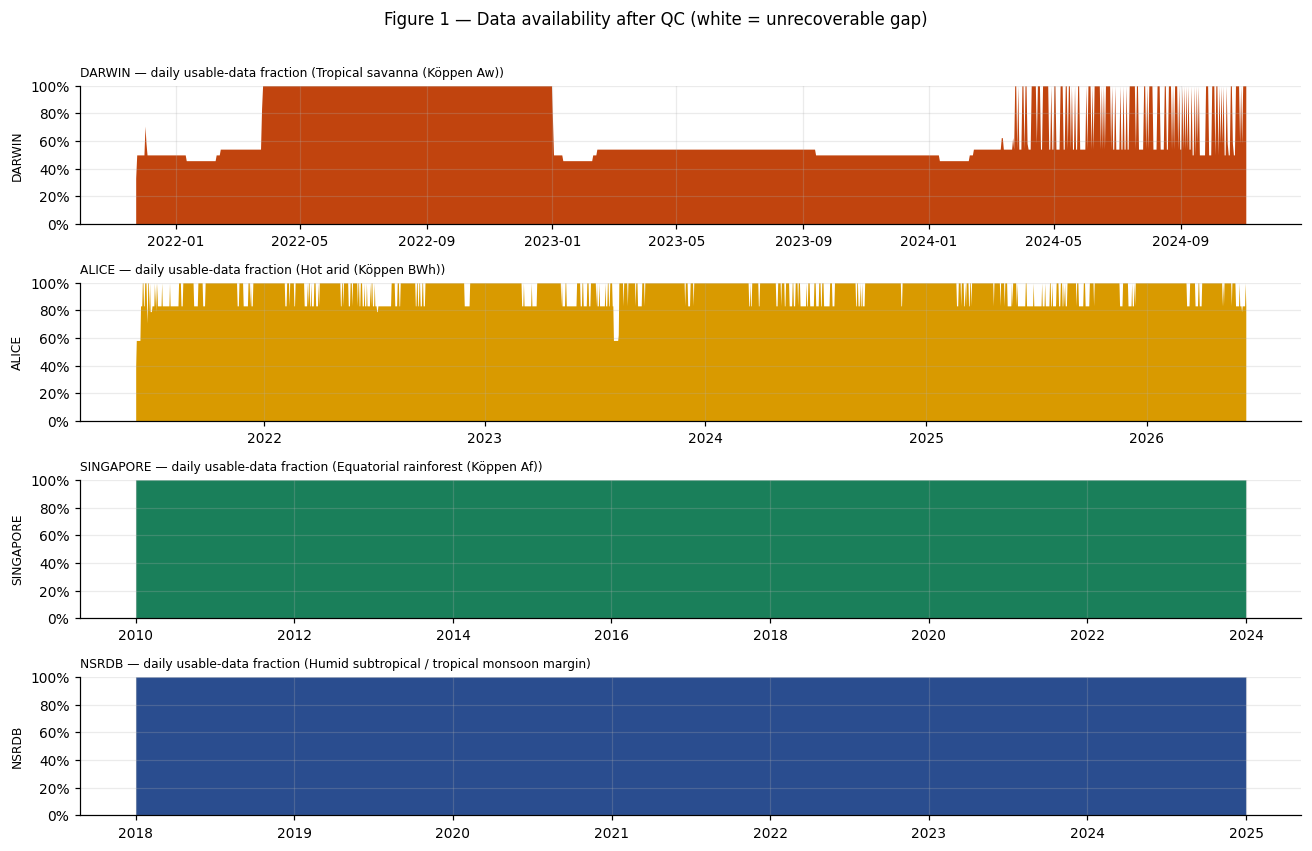

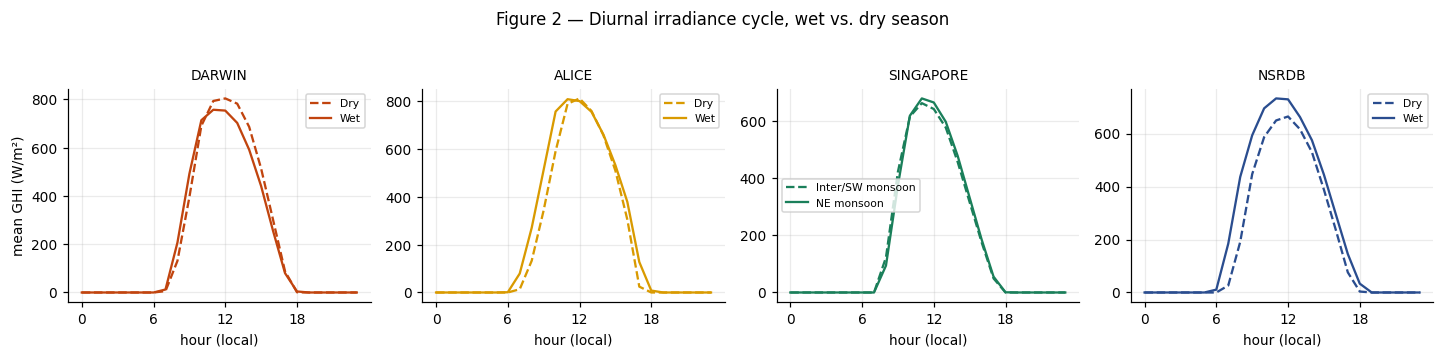

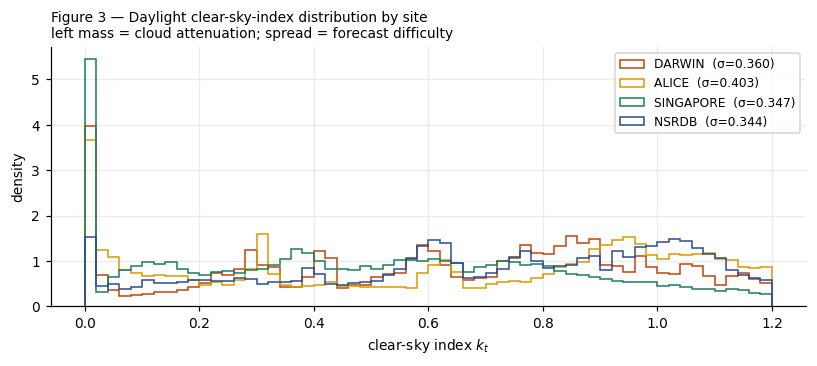

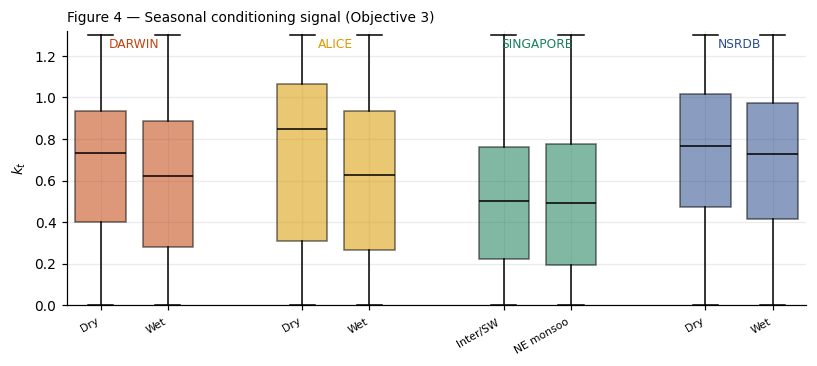

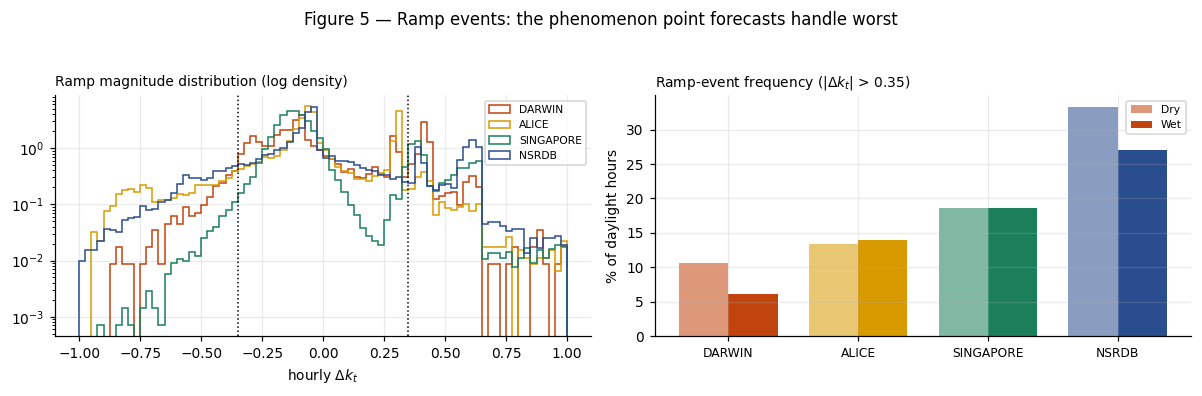

     site           season  ramp_rate
   DARWIN              Dry      10.56
   DARWIN              Wet       6.07
    ALICE              Dry      13.39
    ALICE              Wet      13.96
SINGAPORE Inter/SW monsoon      18.61
SINGAPORE       NE monsoon      18.63
    NSRDB              Dry      33.31
    NSRDB              Wet      27.09


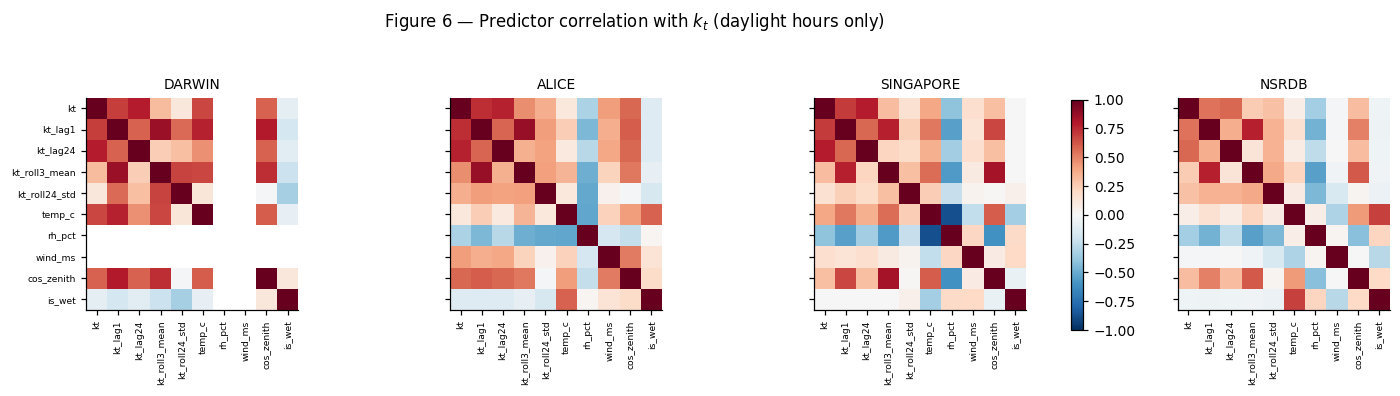

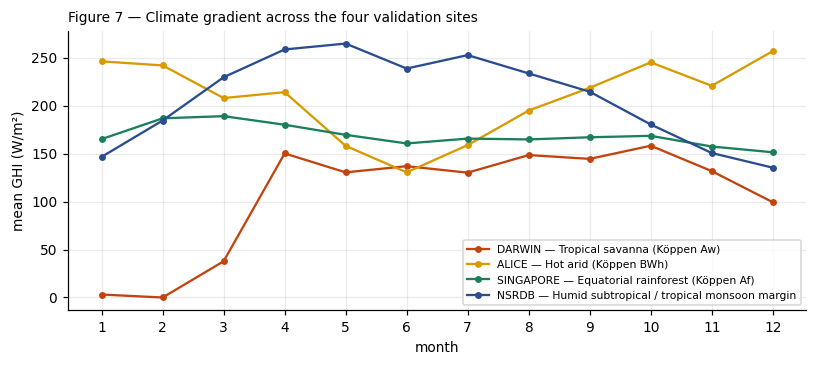

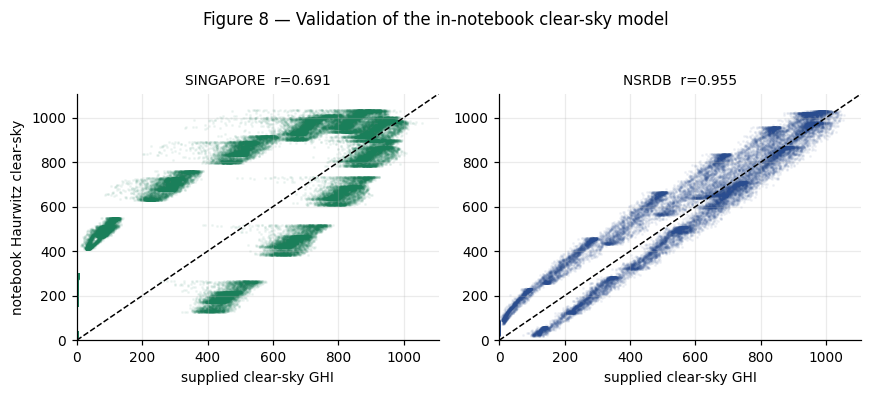

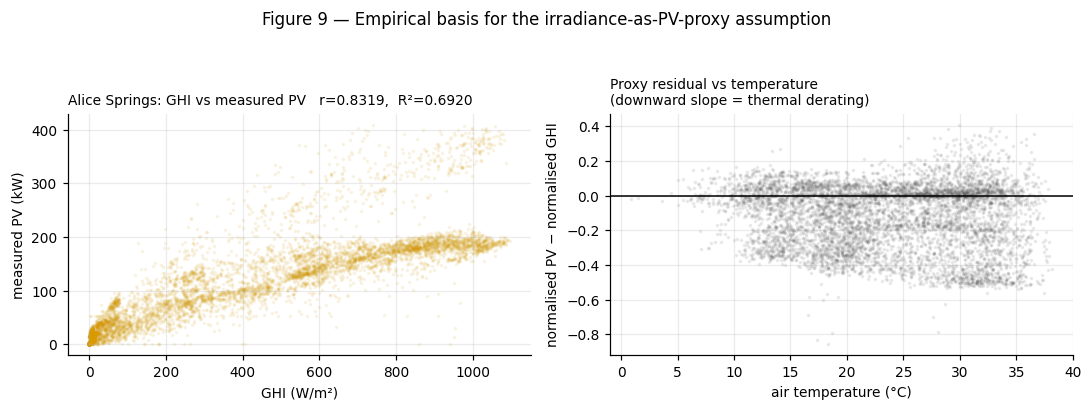

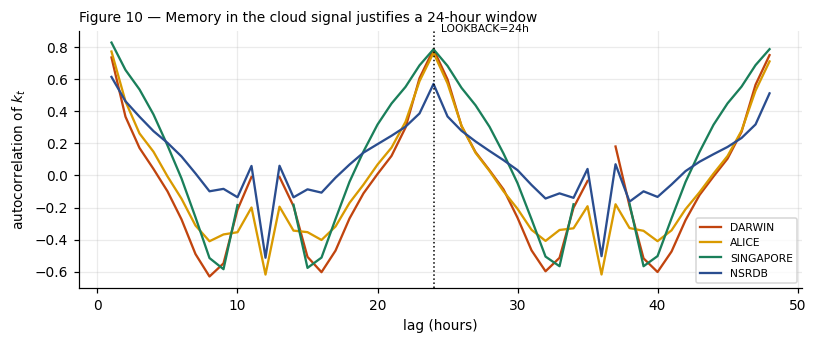

In [ ]:
SITE_COLOR = {"DARWIN": "#c1440e", "ALICE": "#d99a00",
              "SINGAPORE": "#1a7f5a", "NSRDB": "#2a4d8f"}


def _daylight(site):
    return FEAT[(FEAT.site == site) & FEAT.is_daylight]


# ---------------- Figure 1: data availability ---------------------------------
fig, axes = plt.subplots(len(SITES_OK), 1, figsize=(12, 1.9 * len(SITES_OK)), squeeze=False)
for ax, site in zip(axes[:, 0], SITES_OK):
    d = FEAT[FEAT.site == site]
    daily = (d.assign(day=d.ts.dt.floor("D"))
              .groupby("day")
              .agg(avail=("kt_unrecoverable", lambda s: 1 - s.mean())))
    ax.fill_between(daily.index, 0, daily.avail, color=SITE_COLOR[site], lw=0)
    ax.set_ylim(0, 1); ax.set_ylabel(site, fontsize=8)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_title(f"{site} — daily usable-data fraction "
                 f"({SITES[site]['climate']})", fontsize=8, loc="left")
fig.suptitle("Figure 1 — Data availability after QC (white = unrecoverable gap)", y=1.01)
savefig(fig, "fig01_availability"); plt.show()

# ---------------- Figure 2: diurnal cycle by season ----------------------------
fig, axes = plt.subplots(1, len(SITES_OK), figsize=(3.3 * len(SITES_OK), 3.1), squeeze=False)
for ax, site in zip(axes[0], SITES_OK):
    d = FEAT[FEAT.site == site]
    for wet, style in ((0.0, "--"), (1.0, "-")):
        sub = d[d.is_wet == wet]
        if not len(sub):
            continue
        prof = sub.groupby(sub.ts.dt.hour)["ghi_wm2"].mean()
        ax.plot(prof.index, prof.values, style, color=SITE_COLOR[site],
                label=SITES[site]["season_names"][int(wet)])
    ax.set_title(site, fontsize=9); ax.set_xlabel("hour (local)")
    ax.set_xticks([0, 6, 12, 18]); ax.legend(fontsize=7)
axes[0][0].set_ylabel("mean GHI (W/m²)")
fig.suptitle("Figure 2 — Diurnal irradiance cycle, wet vs. dry season", y=1.03)
savefig(fig, "fig02_diurnal"); plt.show()

# ---------------- Figure 3: kt distribution ------------------------------------
fig, ax = plt.subplots(figsize=(7.5, 3.4))
for site in SITES_OK:
    ax.hist(_daylight(site)["kt"].dropna(), bins=60, range=(0, 1.2), density=True,
            histtype="step", lw=1.8, color=SITE_COLOR[site],
            label=f"{site}  (σ={_daylight(site)['kt'].std():.3f})")
ax.set_xlabel("clear-sky index $k_t$"); ax.set_ylabel("density"); ax.legend(fontsize=8)
ax.set_title("Figure 3 — Daylight clear-sky-index distribution by site\n"
             "left mass = cloud attenuation; spread = forecast difficulty", loc="left", fontsize=9)
savefig(fig, "fig03_kt_dist"); plt.show()

# ---------------- Figure 4: seasonal split -------------------------------------
fig, ax = plt.subplots(figsize=(7.5, 3.4))
pos, ticks = [], []
for i, site in enumerate(SITES_OK):
    d = _daylight(site)
    cand = [(0, d[d.is_wet == 0]["kt"].dropna()), (1, d[d.is_wet == 1]["kt"].dropna())]
    cand = [(k, x) for k, x in cand if len(x) > 10]
    if not cand:
        continue
    data = [x for _, x in cand]
    ppos = [i * 3 + k for k, _ in cand]
    bp = ax.boxplot(data, positions=ppos, widths=.75,
                    patch_artist=True, showfliers=False)
    for b in bp["boxes"]:
        b.set_facecolor(SITE_COLOR[site]); b.set_alpha(.55)
    for m in bp["medians"]:
        m.set_color("k")
    pos += ppos
    ticks += [SITES[site]["season_names"][k][:9] for k, _ in cand]
ax.set_xticks(pos); ax.set_xticklabels(ticks, rotation=30, ha="right", fontsize=7)
for i, site in enumerate(SITES_OK):
    ax.text(i * 3 + .5, 1.24, site, ha="center", fontsize=8, color=SITE_COLOR[site])
ax.set_ylabel("$k_t$"); ax.set_ylim(0, 1.32)
ax.set_title("Figure 4 — Seasonal conditioning signal (Objective 3)", loc="left", fontsize=9)
savefig(fig, "fig04_seasonal"); plt.show()

# ---------------- Figure 5: ramp events ----------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
rr = []
for site in SITES_OK:
    d = _daylight(site)
    axes[0].hist(d["dkt"].dropna(), bins=80, range=(-1, 1), density=True,
                 histtype="step", lw=1.6, color=SITE_COLOR[site], label=site)
    for wet in (0.0, 1.0):
        sub = d[d.is_wet == wet]
        if len(sub):
            rr.append({"site": site, "season": SITES[site]["season_names"][int(wet)],
                       "ramp_rate": 100 * sub["is_ramp"].mean()})
axes[0].axvline(-CFG.RAMP_KT_THRESHOLD, color="k", ls=":", lw=1)
axes[0].axvline(CFG.RAMP_KT_THRESHOLD, color="k", ls=":", lw=1)
axes[0].set_yscale("log"); axes[0].set_xlabel("hourly Δ$k_t$"); axes[0].legend(fontsize=7)
axes[0].set_title("Ramp magnitude distribution (log density)", fontsize=9, loc="left")

RAMP = pd.DataFrame(rr)
w = 0.38
for j, site in enumerate(SITES_OK):
    sub = RAMP[RAMP.site == site]
    for k, (_, r) in enumerate(sub.iterrows()):
        axes[1].bar(j + (k - .5) * w, r.ramp_rate, w, color=SITE_COLOR[site],
                    alpha=.55 if k == 0 else 1.0,
                    label=r.season if j == 0 else None)
axes[1].set_xticks(range(len(SITES_OK))); axes[1].set_xticklabels(SITES_OK, fontsize=8)
axes[1].set_ylabel("% of daylight hours"); axes[1].legend(fontsize=7)
axes[1].set_title(f"Ramp-event frequency (|Δ$k_t$| > {CFG.RAMP_KT_THRESHOLD})",
                  fontsize=9, loc="left")
fig.suptitle("Figure 5 — Ramp events: the phenomenon point forecasts handle worst", y=1.04)
savefig(fig, "fig05_ramps"); plt.show()
print(RAMP.round(2).to_string(index=False))

# ---------------- Figure 6: correlation ----------------------------------------
corr_cols = ["kt", "kt_lag1", "kt_lag24", "kt_roll3_mean", "kt_roll24_std",
             "temp_c", "rh_pct", "wind_ms", "cos_zenith", "is_wet"]
fig, axes = plt.subplots(1, len(SITES_OK), figsize=(3.5 * len(SITES_OK), 3.4), squeeze=False)
for ax, site in zip(axes[0], SITES_OK):
    c = _daylight(site)[corr_cols].corr()
    im = ax.imshow(c, vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set_xticks(range(len(corr_cols)))
    ax.set_xticklabels(corr_cols, rotation=90, fontsize=6)
    ax.set_yticks(range(len(corr_cols)))
    ax.set_yticklabels(corr_cols if ax is axes[0][0] else [], fontsize=6)
    ax.set_title(site, fontsize=9); ax.grid(False)
fig.colorbar(im, ax=axes[0], shrink=.8)
fig.suptitle("Figure 6 — Predictor correlation with $k_t$ (daylight hours only)", y=1.04)
savefig(fig, "fig06_corr"); plt.show()

# ---------------- Figure 7: cross-site monthly GHI ------------------------------
fig, ax = plt.subplots(figsize=(7.5, 3.4))
for site in SITES_OK:
    d = FEAT[FEAT.site == site]
    m = d.groupby(d.ts.dt.month)["ghi_wm2"].mean()
    ax.plot(m.index, m.values, "-o", ms=3.5, color=SITE_COLOR[site],
            label=f"{site} — {SITES[site]['climate']}")
ax.set_xticks(range(1, 13)); ax.set_xlabel("month"); ax.set_ylabel("mean GHI (W/m²)")
ax.legend(fontsize=7)
ax.set_title("Figure 7 — Climate gradient across the four validation sites", loc="left", fontsize=9)
savefig(fig, "fig07_crosssite"); plt.show()

# ---------------- Figure 8: clear-sky validation --------------------------------
val_sites = [s for s in SITES_OK if FEAT[(FEAT.site == s)]["ghi_cs_src"].notna().any()]
if val_sites:
    fig, axes = plt.subplots(1, len(val_sites), figsize=(4 * len(val_sites), 3.4), squeeze=False)
    for ax, site in zip(axes[0], val_sites):
        d = _daylight(site).dropna(subset=["ghi_cs_src"])
        ax.scatter(d["ghi_cs_src"], d["ghi_cs"], s=1, alpha=.05, color=SITE_COLOR[site])
        lim = [0, max(d["ghi_cs_src"].max(), d["ghi_cs"].max()) * 1.05]
        ax.plot(lim, lim, "k--", lw=1)
        r = np.corrcoef(d["ghi_cs_src"], d["ghi_cs"])[0, 1]
        ax.set_title(f"{site}  r={r:.3f}", fontsize=9)
        ax.set_xlabel("supplied clear-sky GHI"); ax.set_xlim(lim); ax.set_ylim(lim)
    axes[0][0].set_ylabel("notebook Haurwitz clear-sky")
    fig.suptitle("Figure 8 — Validation of the in-notebook clear-sky model", y=1.04)
    savefig(fig, "fig08_clearsky"); plt.show()

# ---------------- Figure 9: irradiance vs measured PV (the proxy assumption) -----
if "ALICE" in SITES_OK and FEAT[FEAT.site == "ALICE"]["pv_kw"].notna().any():
    d = _daylight("ALICE").dropna(subset=["pv_kw", "ghi_wm2"])
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].scatter(d["ghi_wm2"], d["pv_kw"], s=2, alpha=.08, color=SITE_COLOR["ALICE"])
    r = np.corrcoef(d["ghi_wm2"], d["pv_kw"])[0, 1]
    axes[0].set_xlabel("GHI (W/m²)"); axes[0].set_ylabel("measured PV (kW)")
    axes[0].set_title(f"Alice Springs: GHI vs measured PV   r={r:.4f},  R²={r**2:.4f}",
                      fontsize=9, loc="left")
    resid = (d["pv_kw"] / d["pv_kw"].max()) - (d["ghi_wm2"] / d["ghi_wm2"].max())
    axes[1].scatter(d["temp_c"], resid, s=2, alpha=.08, color="#444")
    axes[1].axhline(0, color="k", lw=1)
    axes[1].set_xlabel("air temperature (°C)")
    axes[1].set_ylabel("normalised PV − normalised GHI")
    axes[1].set_title("Proxy residual vs temperature\n(downward slope = thermal derating)",
                      fontsize=9, loc="left")
    fig.suptitle("Figure 9 — Empirical basis for the irradiance-as-PV-proxy assumption", y=1.05)
    savefig(fig, "fig09_proxy"); plt.show()
    PROXY_R2 = r ** 2
else:
    PROXY_R2 = np.nan

# ---------------- Figure 10: kt autocorrelation --------------------------------
fig, ax = plt.subplots(figsize=(7.5, 3.2))
for site in SITES_OK:
    s = FEAT[FEAT.site == site].set_index("ts")["kt"]
    s = s.where(FEAT[FEAT.site == site].set_index("ts")["is_daylight"])
    ac = [s.autocorr(lag) for lag in range(1, 49)]
    ax.plot(range(1, 49), ac, color=SITE_COLOR[site], label=site)
ax.axvline(CFG.LOOKBACK, color="k", ls=":", lw=1)
ax.text(CFG.LOOKBACK + .5, .9, f"LOOKBACK={CFG.LOOKBACK}h", fontsize=7)
ax.set_xlabel("lag (hours)"); ax.set_ylabel("autocorrelation of $k_t$"); ax.legend(fontsize=7)
ax.set_title("Figure 10 — Memory in the cloud signal justifies a 24-hour window",
             loc="left", fontsize=9)
savefig(fig, "fig10_acf"); plt.show()

### 5.1 Automated feature screening — a correctness check, not a convenience

Darwin's confirmed data is irradiance-only. It has **no relative-humidity and no wind
measurement at all**, so at the primary modelling site those two columns are 100% synthetic —
filled from a climatology that is itself derived from nothing.

Leaving them in would silently corrupt Objective 8. The Darwin-trained model would learn that
`rh_pct` and `wind_ms` are constants, and then be asked to predict at Singapore and NSRDB where
those same columns carry real, varying signal. That is a covariate shift introduced by the
pipeline rather than by the climate — it would make the cross-climate transfer numbers wrong in
a way that no amount of debugging downstream would reveal.

The screen below is therefore mandatory, not cosmetic: any feature that is more than 50%
imputed or effectively constant at the primary site is removed from the feature set **at every
site**, so all four sites are modelled on an identical, honestly-populated feature vector.

In [ ]:
def screen_features(site, candidates):
    d = FEAT[FEAT.site == site]
    rows, keep = [], []
    for f in candidates:
        icol = f"{f}_imputed"
        imp = float(d[icol].mean()) if icol in d.columns else 0.0
        sd = float(pd.to_numeric(d[f], errors="coerce").std(skipna=True) or 0.0)
        drop = (imp > 0.50) or (sd < 1e-6) or not np.isfinite(sd)
        rows.append({"feature": f, "imputed_frac": round(imp, 4), "std_at_primary": round(sd, 6),
                     "decision": "DROP" if drop else "keep",
                     "reason": ("not measured at primary site — would be a constant at train "
                                "time and a live variable at transfer time" if imp > 0.50 else
                                "zero variance at primary site" if drop else "")})
        if not drop:
            keep.append(f)
    return keep, pd.DataFrame(rows)


_kept_base, FEATURE_SCREEN = screen_features(
    "DARWIN" if "DARWIN" in SITES_OK else SITES_OK[0], BASE_FEATURES)
print("FEATURE SCREEN AT PRIMARY MODELLING SITE")
print(FEATURE_SCREEN.to_string(index=False))
save_table(FEATURE_SCREEN, "feature_screen")

BASE_FEATURES = _kept_base
ALL_FEATURES = BASE_FEATURES + [SEASON_FEATURE]
print(f"\nModelling feature vector ({len(ALL_FEATURES)}): {ALL_FEATURES}")

FEATURE SCREEN AT PRIMARY MODELLING SITE
       feature  imputed_frac  std_at_primary decision                                                                                                reason
            kt        0.0285        0.334211     keep                                                                                                      
       kt_lag1        0.0000        0.334211     keep                                                                                                      
       kt_lag2        0.0000        0.334211     keep                                                                                                      
       kt_lag3        0.0000        0.334219     keep                                                                                                      
      kt_lag24        0.0000        0.334053     keep                                                                                                      
 kt_roll3_mean        0

## PART 6 — Supervised problem construction

### 6.1 What is being predicted, and why it is $k_t$ rather than GHI

The models forecast **clear-sky index $k_t$ at $t+1$ h**, and every reported metric is then
converted back to W/m² through $\widehat{GHI} = \hat{k_t}\cdot GHI_{cs}$.

This matters for the integrity of the comparison. Roughly 80–90% of the variance of raw GHI is
the deterministic daily solar cycle. A model trained on GHI is largely rewarded for learning
sunrise, which inflates $R^2$ to ~0.95 at every site and compresses the differences between
architectures — exactly the differences this study exists to measure. Forecasting $k_t$ removes
the astronomy and leaves the meteorology, which is the actual forecasting problem.

Because $GHI_{cs}>0$ is a known positive scalar at each timestamp, the transform is monotone:
predicted quantiles of $k_t$ map directly to predicted quantiles of GHI, so CRPS, pinball, PICP
and MIW remain valid after conversion.

### 6.2 Splitting

Chronological 70 / 15 / 15, never shuffled. Shuffling a lagged time series lets the model see
neighbouring hours of a test day during training — the most common way a solar forecasting result
becomes silently meaningless. Scalers are fitted on training rows only.

Targets are restricted to **daylight hours** ($GHI_{cs} > 20$ W/m²). Night hours are structural
zeros; including them would let a model score well by predicting zero half the time.

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.keras.utils.set_random_seed(CFG.SEED)
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU") or "none")


def build_supervised(d: pd.DataFrame, feats, target="kt"):
    """(X, y, meta) with strictly backward-looking windows and no NaN leakage."""
    from numpy.lib.stride_tricks import sliding_window_view
    d = d.sort_values("ts").reset_index(drop=True)
    F = d[feats].to_numpy(dtype=np.float32)
    y = d[target].to_numpy(dtype=np.float32)
    L, H = CFG.LOOKBACK, CFG.HORIZON
    n = len(d) - L - H + 1
    if n <= 10:
        return None
    Xall = sliding_window_view(F, (L, F.shape[1]))[:, 0]          # (len-L+1, L, nf)
    X = Xall[:n]
    tgt_idx = np.arange(L + H - 1, L + H - 1 + n)
    yv = y[tgt_idx]

    ok = (np.isfinite(X).all(axis=(1, 2)) & np.isfinite(yv)
          & d["is_daylight"].to_numpy()[tgt_idx])
    X, yv, tgt_idx = np.ascontiguousarray(X[ok]), yv[ok], tgt_idx[ok]
    meta = d.loc[tgt_idx, ["ts", "ghi_cs", "is_wet", "is_ramp", "ghi_wm2"]].reset_index(drop=True)
    return X, yv, meta


def chrono_split(X, y, meta):
    n = len(y)
    a, b = int(n * CFG.TRAIN_FRAC), int(n * (CFG.TRAIN_FRAC + CFG.VAL_FRAC))
    sl = {"train": slice(0, a), "val": slice(a, b), "test": slice(b, n)}
    return {k: (X[v], y[v], meta.iloc[v].reset_index(drop=True)) for k, v in sl.items()}


class Standardiser:
    """Per-feature z-scaling fitted on training windows only."""

    def fit(self, X):
        flat = X.reshape(-1, X.shape[-1])
        self.mu = np.nanmean(flat, axis=0)
        self.sd = np.nanstd(flat, axis=0)
        self.sd[self.sd < 1e-8] = 1.0
        return self

    def __call__(self, X):
        return ((X - self.mu) / self.sd).astype(np.float32)


DATASETS = {}
for site in SITES_OK:
    d = FEAT[FEAT.site == site]
    built = build_supervised(d, ALL_FEATURES)
    if built is None:
        log(f"{site}: too few usable windows — excluded from modelling", "warn")
        continue
    X, y, meta = built
    DATASETS[site] = chrono_split(X, y, meta)
    tr, va, te = (DATASETS[site][k][0].shape[0] for k in ("train", "val", "test"))
    log(f"{site:<10} windows: train {tr:,} | val {va:,} | test {te:,} | "
        f"X={X.shape} | {X.nbytes/1e6:.0f} MB", "ok")

MODEL_SITE = "DARWIN" if "DARWIN" in DATASETS else list(DATASETS)[0]
print(f"\nPrimary modelling site: {MODEL_SITE}  ({SITES[MODEL_SITE]['climate']})")

TensorFlow 2.20.0 | GPU: none
[ 3243.0s |   1069MB]  ok DARWIN     windows: train 2,480 | val 532 | test 532 | X=(3544, 24, 16) | 5 MB
[ 3243.2s |   1139MB]  ok ALICE      windows: train 9,599 | val 2,057 | test 2,057 | X=(13713, 24, 16) | 21 MB
[ 3243.8s |   1227MB]  ok SINGAPORE  windows: train 40,001 | val 8,572 | test 8,572 | X=(57145, 24, 16) | 88 MB
[ 3244.0s |   1295MB]  ok NSRDB      windows: train 20,565 | val 4,407 | test 4,407 | X=(29379, 24, 16) | 45 MB

Primary modelling site: DARWIN  (Tropical savanna (Köppen Aw))


## PART 7 — Model architectures

Four models, matched in capacity so that any performance difference is attributable to the
*treatment of uncertainty* and not to parameter count:

| Model | Type | Output | Loss |
|---|---|---|---|
| LSTM | deterministic | 1 point | MSE |
| GRU | deterministic | 1 point | MSE |
| MC-Dropout LSTM | probabilistic | 50 stochastic passes | MSE (dropout left active at inference) |
| QR-GRU | probabilistic | 7 quantiles | pinball (quantile) loss |

All use a single recurrent layer of 64 units followed by a 32-unit dense block. MC-Dropout keeps
dropout active at prediction time — that is the entire mechanism by which a deterministic
architecture becomes an approximate Bayesian one (Gal & Ghahramani, 2016). QR-GRU instead learns
the conditional quantiles directly; its outputs are sorted post-hoc to prevent quantile crossing.

In [ ]:
def pinball_loss(quantiles):
    q = tf.constant(quantiles, dtype=tf.float32)

    def loss(y_true, y_pred):
        e = tf.cast(y_true, tf.float32)[:, None] - y_pred
        return tf.reduce_mean(tf.maximum(q * e, (q - 1.0) * e))
    loss.__name__ = "pinball"
    return loss


def build_model(kind, n_features):
    inp = keras.Input(shape=(CFG.LOOKBACK, n_features))
    if kind == "LSTM":
        x = layers.LSTM(CFG.UNITS)(inp)
        x = layers.Dense(32, activation="relu")(x)
        out = layers.Dense(1)(x)
        model = keras.Model(inp, out)
        model.compile(keras.optimizers.Adam(1e-3), loss="mse")

    elif kind == "GRU":
        x = layers.GRU(CFG.UNITS)(inp)
        x = layers.Dense(32, activation="relu")(x)
        out = layers.Dense(1)(x)
        model = keras.Model(inp, out)
        model.compile(keras.optimizers.Adam(1e-3), loss="mse")

    elif kind == "MC-Dropout LSTM":
        x = layers.LSTM(CFG.UNITS, dropout=CFG.DROPOUT)(inp)
        x = layers.Dropout(CFG.DROPOUT)(x, training=True)
        x = layers.Dense(32, activation="relu")(x)
        x = layers.Dropout(CFG.DROPOUT)(x, training=True)
        out = layers.Dense(1)(x)
        model = keras.Model(inp, out)
        model.compile(keras.optimizers.Adam(1e-3), loss="mse")

    elif kind == "QR-GRU":
        x = layers.GRU(CFG.UNITS)(inp)
        x = layers.Dense(32, activation="relu")(x)
        out = layers.Dense(len(CFG.QUANTILES))(x)
        model = keras.Model(inp, out)
        model.compile(keras.optimizers.Adam(1e-3), loss=pinball_loss(CFG.QUANTILES))
    else:
        raise ValueError(kind)
    return model


MODEL_KINDS = ["LSTM", "GRU", "MC-Dropout LSTM", "QR-GRU"]
PROBABILISTIC = {"MC-Dropout LSTM", "QR-GRU"}


def fit_model(kind, split, scaler, tag=""):
    Xtr, ytr, _ = split["train"]
    Xva, yva, _ = split["val"]
    tf.keras.utils.set_random_seed(CFG.SEED)
    m = build_model(kind, Xtr.shape[-1])
    hist = m.fit(scaler(Xtr), ytr,
                 validation_data=(scaler(Xva), yva),
                 epochs=CFG.EPOCHS, batch_size=CFG.BATCH, verbose=0,
                 callbacks=[keras.callbacks.EarlyStopping(
                     monitor="val_loss", patience=CFG.PATIENCE,
                     restore_best_weights=True)])
    log(f"  trained {kind:<17}{tag}  epochs={len(hist.history['loss'])}"
        f"  val_loss={min(hist.history['val_loss']):.5f}", "ok")
    return m, hist


def predict(kind, model, Xs):
    """Return (point_estimate, quantile_matrix or None, sample_matrix or None) in kt space."""
    if kind == "MC-Dropout LSTM":
        # Reseeded every call so the stochastic forward passes are reproducible
        # and identical whenever the same model is scored twice.
        tf.random.set_seed(CFG.SEED)
        S = np.stack([model(Xs, training=True).numpy().ravel()
                      for _ in range(CFG.MC_PASSES)], axis=1)
        return S.mean(1), np.quantile(S, CFG.QUANTILES, axis=1).T, S
    if kind == "QR-GRU":
        Q = np.sort(model.predict(Xs, verbose=0), axis=1)      # enforce monotonicity
        med = CFG.QUANTILES.index(0.50)
        return Q[:, med], Q, None
    return model.predict(Xs, verbose=0).ravel(), None, None

## PART 8 — Evaluation metrics

Point accuracy (Objective 1) and probabilistic calibration (Objective 2) are computed in the same
function so no model is ever scored on a different subset than another.

* **RMSE / MAE / R²** — reported in **W/m²** after reconstruction, plus nRMSE as a % of mean
  daylight GHI so sites with different irradiance levels remain comparable.
* **CRPS** — the ensemble form for MC-Dropout; the quantile-integral form
  $\text{CRPS}=2\int_0^1 \text{PL}_\tau\,d\tau$ for QR-GRU. For a deterministic point forecast the
  predictive distribution is a Dirac mass, for which CRPS reduces exactly to MAE — so the column
  is filled for all four models and the comparison is like-for-like rather than blank.
* **Pinball loss** at τ = 0.10 / 0.50 / 0.90, as specified in the proposal.
* **PICP / MIW / PINAW** for the nominal 80% interval (q10–q90). **Note:** the proposal's
  decision rule quotes "PICP ≥ 0.90" against a 10th/90th-percentile interval, whose nominal
  coverage is 80%, not 90%. Both are reported — PICP₈₀ against the q10–q90 band and PICP₉₀
  against q05–q95 — so the threshold can be stated against the interval it actually belongs to.

In [ ]:
def crps_ensemble(S, y):
    M = S.shape[1]
    t1 = np.abs(S - y[:, None]).mean(axis=1)
    s = np.sort(S, axis=1)
    i = np.arange(1, M + 1)
    t2 = (2.0 / (M * M)) * ((2 * i - M - 1) * s).sum(axis=1)
    return t1 - 0.5 * t2


def pinball(y, q_pred, tau):
    e = y - q_pred
    return np.maximum(tau * e, (tau - 1) * e)


_trapz = getattr(np, "trapezoid", None) or np.trapz   # numpy 2.x renamed trapz


def crps_from_quantiles(Q, y, taus):
    """CRPS = 2 * integral_0^1 PL_tau dtau (Gneiting & Raftery, 2007).

    Integrated over the fitted quantile grid, so tail mass outside
    [min(tau), max(tau)] is not captured; this slightly favours the quantile
    model relative to the ensemble CRPS and is reported as a limitation.
    """
    pl = np.array([pinball(y, Q[:, j], t).mean() for j, t in enumerate(taus)])
    return 2.0 * _trapz(pl, taus)


def evaluate(kind, point_kt, Q_kt, S_kt, y_kt, meta, subset=None):
    cs = meta["ghi_cs"].to_numpy()
    m = np.ones(len(y_kt), bool) if subset is None else np.asarray(subset)
    if m.sum() < 10:
        return None

    yh = (point_kt * cs).clip(0)[m]
    yt = (y_kt * cs)[m]
    err = yh - yt
    ss = ((yt - yt.mean()) ** 2).sum()

    r = {"model": kind, "n": int(m.sum()),
         "RMSE_Wm2": float(np.sqrt((err ** 2).mean())),
         "MAE_Wm2": float(np.abs(err).mean()),
         "R2": float(1 - (err ** 2).sum() / ss) if ss > 0 else np.nan,
         "nRMSE_%": float(100 * np.sqrt((err ** 2).mean()) / yt.mean()) if yt.mean() > 0 else np.nan}

    taus = np.array(CFG.QUANTILES)
    if Q_kt is not None:
        Qw = np.clip(Q_kt * cs[:, None], 0, None)[m]
        lo = Qw[:, CFG.QUANTILES.index(CFG.PI_LOW)]
        hi = Qw[:, CFG.QUANTILES.index(CFG.PI_HIGH)]
        r["CRPS_Wm2"] = float(crps_ensemble(np.clip(S_kt * cs[:, None], 0, None)[m], yt).mean()
                              if S_kt is not None else crps_from_quantiles(Qw, yt, taus))
        for t in (0.10, 0.50, 0.90):
            j = CFG.QUANTILES.index(t)
            r[f"Pinball_q{int(t*100)}"] = float(pinball(yt, Qw[:, j], t).mean())
        r["PICP_80"] = float(((yt >= lo) & (yt <= hi)).mean())
        r["MIW_Wm2"] = float((hi - lo).mean())
        r["PINAW_%"] = float(100 * (hi - lo).mean() / (yt.max() - yt.min()))
        lo95 = Qw[:, CFG.QUANTILES.index(0.05)]
        hi95 = Qw[:, CFG.QUANTILES.index(0.95)]
        r["PICP_90"] = float(((yt >= lo95) & (yt <= hi95)).mean())
    else:
        # Dirac predictive distribution: CRPS == MAE. Intervals undefined by construction.
        r["CRPS_Wm2"] = r["MAE_Wm2"]
        for t in (0.10, 0.50, 0.90):
            r[f"Pinball_q{int(t*100)}"] = float(pinball(yt, yh, t).mean())
        r["PICP_80"] = r["MIW_Wm2"] = r["PINAW_%"] = r["PICP_90"] = np.nan
    return r


def persistence_baseline(split, feats=ALL_FEATURES):
    """Smart persistence: k_t(t+1) = k_t(t). The benchmark every solar paper must beat."""
    X, y, meta = split["test"]
    j = feats.index("kt")
    return X[:, -1, j], meta, y

## PART 9 — Main experiment: four architectures on the tropical target site

Objectives 1, 2 and 4–5. Trained on Darwin with seasonal conditioning active.

[ 3348.0s |   1318MB]  ok   trained LSTM               epochs=21  val_loss=0.04587
[ 3406.2s |   1354MB]  ok   trained GRU                epochs=60  val_loss=0.03998
[ 3431.9s |   1384MB]  ok   trained MC-Dropout LSTM    epochs=30  val_loss=0.04784
[ 3492.8s |   1415MB]  ok   trained QR-GRU             epochs=55  val_loss=0.04067

MAIN RESULTS — DARWIN test set, t+1h, daylight hours only
                 model   n  RMSE_Wm2  MAE_Wm2    R2  nRMSE_%  CRPS_Wm2  Pinball_q10  Pinball_q50  Pinball_q90  PICP_80  MIW_Wm2  PINAW_%  PICP_90
Persistence (baseline) 532   146.795  114.307 0.781   35.954   114.307       62.388       57.154       51.919      NaN      NaN      NaN      NaN
                  LSTM 532   171.373  101.241 0.701   41.974   101.241       69.386       50.620       31.854      NaN      NaN      NaN      NaN
                   GRU 532   154.587   92.314 0.757   37.863    92.314       62.442       46.157       29.871      NaN      NaN      NaN      NaN
       MC-Dropout LSTM 53

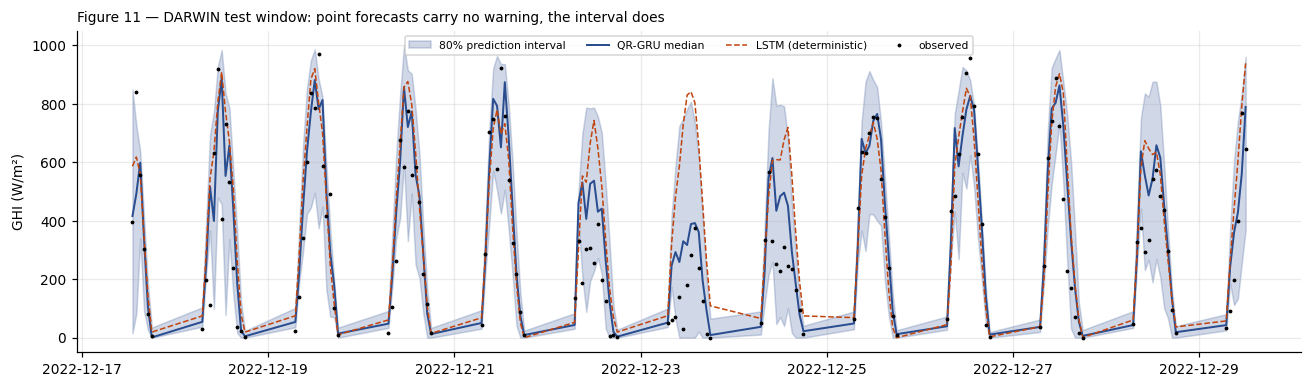

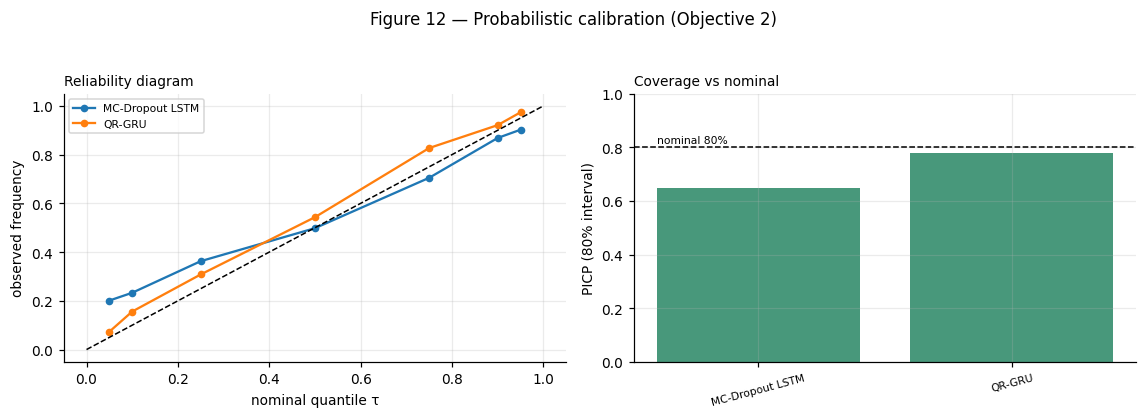

In [ ]:
SCALERS, MODELS, PREDS = {}, {}, {}


def run_main():
    split = DATASETS[MODEL_SITE]
    sc = Standardiser().fit(split["train"][0])
    SCALERS[MODEL_SITE] = sc
    Xte, yte, mte = split["test"]
    Xte_s = sc(Xte)

    rows = []
    pk, pm, py = persistence_baseline(split)
    r0 = evaluate("Persistence (baseline)", pk, None, None, py, pm)
    if r0:
        rows.append(r0)

    for kind in MODEL_KINDS:
        model, hist = fit_model(kind, split, sc)
        point, Q, S = predict(kind, model, Xte_s)
        MODELS[kind] = model
        PREDS[kind] = (point, Q, S, yte, mte)
        r = evaluate(kind, point, Q, S, yte, mte)
        if r:
            rows.append(r)
    return pd.DataFrame(rows)


RESULTS_MAIN = run_main()
print(f"\nMAIN RESULTS — {MODEL_SITE} test set, t+{CFG.HORIZON}h, daylight hours only")
print("=" * 118)
print(RESULTS_MAIN.round(3).to_string(index=False))
save_table(RESULTS_MAIN, "results_main")

# ---------------- Figure 11: forecast vs truth with uncertainty band -----------
qr_kind = "QR-GRU" if "QR-GRU" in PREDS else None
if qr_kind:
    point, Q, S, yte, mte = PREDS[qr_kind]
    cs = mte["ghi_cs"].to_numpy()
    n0 = min(len(yte) - 1, 0)
    seg = slice(n0, n0 + 24 * 6)
    fig, ax = plt.subplots(figsize=(12, 3.6))
    t = mte["ts"].iloc[seg]
    ax.fill_between(t, (Q[seg, CFG.QUANTILES.index(0.10)] * cs[seg]).clip(0),
                    (Q[seg, CFG.QUANTILES.index(0.90)] * cs[seg]).clip(0),
                    color="#2a4d8f", alpha=.22, label="80% prediction interval")
    ax.plot(t, (point[seg] * cs[seg]).clip(0), color="#2a4d8f", lw=1.3, label="QR-GRU median")
    if "LSTM" in PREDS:
        ax.plot(t, (PREDS["LSTM"][0][seg] * cs[seg]).clip(0), color="#c1440e",
                lw=1.0, ls="--", label="LSTM (deterministic)")
    ax.plot(t, (yte[seg] * cs[seg]), "k.", ms=3, label="observed")
    ax.set_ylabel("GHI (W/m²)"); ax.legend(fontsize=7, ncol=4)
    ax.set_title(f"Figure 11 — {MODEL_SITE} test window: point forecasts carry no warning, "
                 "the interval does", loc="left", fontsize=9)
    savefig(fig, "fig11_forecast"); plt.show()

# ---------------- Figure 12: calibration / reliability -------------------------
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6))
for kind in [k for k in MODEL_KINDS if k in PROBABILISTIC and k in PREDS]:
    point, Q, S, yte, mte = PREDS[kind]
    cs = mte["ghi_cs"].to_numpy()
    yt = yte * cs
    obs = [float((yt <= np.clip(Q[:, j] * cs, 0, None)).mean()) for j in range(len(CFG.QUANTILES))]
    axes[0].plot(CFG.QUANTILES, obs, "-o", ms=4, label=kind)
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_xlabel("nominal quantile τ"); axes[0].set_ylabel("observed frequency")
axes[0].set_title("Reliability diagram", fontsize=9, loc="left"); axes[0].legend(fontsize=7)

sub = RESULTS_MAIN.dropna(subset=["PICP_80"])
axes[1].bar(sub.model, sub.PICP_80, color="#1a7f5a", alpha=.8)
axes[1].axhline(0.80, color="k", ls="--", lw=1)
axes[1].text(-.4, .815, "nominal 80%", fontsize=7)
axes[1].set_ylim(0, 1); axes[1].set_ylabel("PICP (80% interval)")
axes[1].tick_params(axis="x", rotation=15, labelsize=7)
axes[1].set_title("Coverage vs nominal", fontsize=9, loc="left")
fig.suptitle("Figure 12 — Probabilistic calibration (Objective 2)", y=1.04)
savefig(fig, "fig12_calibration"); plt.show()

## PART 10 — Seasonal conditioning and ramp-event subgroup analysis

Objective 3. Each architecture is retrained with the `is_wet` feature removed, and scored on the
identical test rows. The difference is the causal contribution of seasonal conditioning, isolated
from every other factor. The same fitted models are then rescored on the ramp-event subgroup only
— the regime where Wan et al. (2017) show deterministic models to be overconfident.

[ 5208.5s |   1459MB]  ok   trained LSTM               [no season]  epochs=40  val_loss=0.04174
[ 5253.0s |   1491MB]  ok   trained GRU                [no season]  epochs=45  val_loss=0.03828
[ 5294.5s |   1517MB]  ok   trained MC-Dropout LSTM    [no season]  epochs=51  val_loss=0.04215
[ 5351.8s |   1546MB]  ok   trained QR-GRU             [no season]  epochs=48  val_loss=0.04092

SEASONAL CONDITIONING ABLATION (Objective 3)
                   CRPS_Wm2                    PICP_80                   RMSE_Wm2                               
conditioning    with season without season with season without season with season without season Δ improvement %
model                                                                                                           
GRU                  92.314         84.559         NaN            NaN     154.587        137.020         -12.821
LSTM                101.241         95.286         NaN            NaN     171.373        160.000          -7.108
MC-Dr

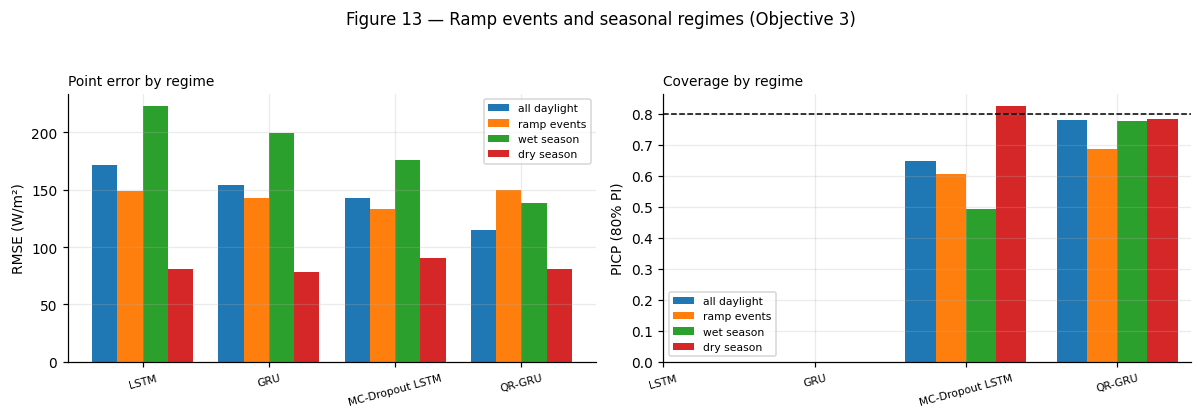

In [ ]:
def run_ablation():
    site = MODEL_SITE
    d = FEAT[FEAT.site == site]
    built = build_supervised(d, BASE_FEATURES)          # season feature removed
    X, y, meta = built
    split_ns = chrono_split(X, y, meta)
    sc_ns = Standardiser().fit(split_ns["train"][0])
    Xte_ns = sc_ns(split_ns["test"][0])
    yte_ns, mte_ns = split_ns["test"][1], split_ns["test"][2]

    rows = []
    for kind in MODEL_KINDS:
        m_ns, _ = fit_model(kind, split_ns, sc_ns, tag="  [no season]")
        p, Q, S = predict(kind, m_ns, Xte_ns)
        r = evaluate(kind, p, Q, S, yte_ns, mte_ns)
        if r:
            r["conditioning"] = "without season"
            rows.append(r)

        r2 = dict(RESULTS_MAIN[RESULTS_MAIN.model == kind].iloc[0])
        r2["conditioning"] = "with season"
        rows.append(r2)
    return pd.DataFrame(rows)


ABLATION = run_ablation()
piv = ABLATION.pivot_table(index="model", columns="conditioning",
                           values=["RMSE_Wm2", "CRPS_Wm2", "PICP_80"])
piv[("RMSE_Wm2", "Δ improvement %")] = 100 * (
    piv[("RMSE_Wm2", "without season")] - piv[("RMSE_Wm2", "with season")]
) / piv[("RMSE_Wm2", "without season")]
print("\nSEASONAL CONDITIONING ABLATION (Objective 3)")
print("=" * 110)
print(piv.round(3).to_string())
save_table(ABLATION, "results_ablation")

# ---- ramp-event subgroup ------------------------------------------------------
ramp_rows = []
for kind in MODEL_KINDS:
    if kind not in PREDS:
        continue
    point, Q, S, yte, mte = PREDS[kind]
    for label, mask in (("all daylight", np.ones(len(yte), bool)),
                        ("ramp events", mte["is_ramp"].to_numpy().astype(bool)),
                        ("wet season", mte["is_wet"].to_numpy() > 0),
                        ("dry season", mte["is_wet"].to_numpy() == 0)):
        r = evaluate(kind, point, Q, S, yte, mte, subset=mask)
        if r:
            r["subgroup"] = label
            ramp_rows.append(r)
SUBGROUP = pd.DataFrame(ramp_rows)
_want_sg = {"all daylight", "ramp events", "wet season", "dry season"}
_missing_sg = _want_sg - set(SUBGROUP.get("subgroup", pd.Series(dtype=str)))
if _missing_sg:
    log(f"subgroup(s) with <10 test hours, omitted: {sorted(_missing_sg)} "
        f"(the chronological test split does not span them)", "warn")
print("\nSUBGROUP ANALYSIS — where uncertainty quantification earns its keep")
print("=" * 118)
print(SUBGROUP[["model", "subgroup", "n", "RMSE_Wm2", "CRPS_Wm2",
                "PICP_80", "MIW_Wm2"]].round(3).to_string(index=False))
save_table(SUBGROUP, "results_subgroup")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
order = [k for k in MODEL_KINDS if k in set(SUBGROUP.model)]
w = 0.2
for i, sg in enumerate(["all daylight", "ramp events", "wet season", "dry season"]):
    s = SUBGROUP[SUBGROUP.subgroup == sg].set_index("model").reindex(order)
    axes[0].bar(np.arange(len(order)) + (i - 1.5) * w, s.RMSE_Wm2, w, label=sg)
    axes[1].bar(np.arange(len(order)) + (i - 1.5) * w, s.PICP_80, w, label=sg)
for ax, ttl, yl in ((axes[0], "Point error by regime", "RMSE (W/m²)"),
                    (axes[1], "Coverage by regime", "PICP (80% PI)")):
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels(order, rotation=15, fontsize=7)
    ax.set_title(ttl, fontsize=9, loc="left"); ax.set_ylabel(yl); ax.legend(fontsize=7)
axes[1].axhline(.8, color="k", ls="--", lw=1)
fig.suptitle("Figure 13 — Ramp events and seasonal regimes (Objective 3)", y=1.04)
savefig(fig, "fig13_subgroup"); plt.show()

## PART 11 — Proxy validation: does forecasting irradiance stand in for forecasting power?

Objective 1 (secondary). This is the load-bearing assumption of the whole project: because Darwin
has no measured PV, the study forecasts irradiance and claims it is the precursor to power.
Alice Springs is the only site with **co-located irradiance and measured PV output**, so the
assumption can be tested rather than asserted.

The same GRU is trained twice on identical inputs and identical windows, changing only the target:
once on $k_t$ (irradiance), once on PV output normalised to plant capacity. If the normalised
errors are close, the proxy is defensible and the Darwin result transfers. If they diverge, the
gap is the quantified cost of the proxy — which is itself a reportable finding.

In [ ]:
def run_proxy_validation():
    if "ALICE" not in SITES_OK:
        return None
    d = FEAT[FEAT.site == "ALICE"].copy()
    if d["pv_kw"].notna().sum() < 500:
        log("Alice PV column empty — proxy validation skipped", "warn")
        return None

    cap = float(np.nanpercentile(d["pv_kw"], 99.5))
    d["pv_norm"] = (d["pv_kw"] / cap).clip(0, 1.2)
    # interpolate short PV gaps only, on the same policy used for kt
    miss = d["pv_norm"].isna() & d["is_daylight"]
    runs = _gap_lengths(miss)
    d["pv_norm"] = np.where(miss & (runs <= CFG.MAX_INTERP_GAP_H),
                            d["pv_norm"].interpolate(limit=CFG.MAX_INTERP_GAP_H,
                                                     limit_area="inside"),
                            d["pv_norm"])

    rows = []
    for target, label in (("kt", "irradiance (kt)"), ("pv_norm", "measured PV (normalised)")):
        built = build_supervised(d, ALL_FEATURES, target=target)
        if built is None:
            continue
        X, y, meta = built
        sp = chrono_split(X, y, meta)
        sc = Standardiser().fit(sp["train"][0])
        m, _ = fit_model("GRU", sp, sc, tag=f"  [proxy: {label}]")
        p = m.predict(sc(sp["test"][0]), verbose=0).ravel()
        yt = sp["test"][1]
        err = p - yt
        rows.append({"target": label, "n_test": len(yt),
                     "RMSE_norm": float(np.sqrt((err ** 2).mean())),
                     "MAE_norm": float(np.abs(err).mean()),
                     "nRMSE_%": float(100 * np.sqrt((err ** 2).mean()) / yt.mean()),
                     "R2": float(1 - (err ** 2).sum() / ((yt - yt.mean()) ** 2).sum())})
    return pd.DataFrame(rows)


PROXY = run_proxy_validation()
if PROXY is not None and len(PROXY) == 2:
    delta = PROXY.iloc[1]["nRMSE_%"] - PROXY.iloc[0]["nRMSE_%"]
    print("\nPROXY VALIDATION — irradiance target vs measured-power target (Alice Springs, GRU)")
    print("=" * 100)
    print(PROXY.round(4).to_string(index=False))
    print(f"\n  Static GHI→PV coupling at this site (Figure 9): R² = {PROXY_R2:.4f}")
    print(f"  Forecast-accuracy delta from using irradiance as the target: "
          f"{delta:+.2f} percentage points of nRMSE")
    print(textwrap.fill(
        "Interpretation: a small positive delta means power is marginally harder to forecast than "
        "irradiance (thermal derating, soiling and inverter clipping add variance that irradiance "
        "does not contain), and the Darwin irradiance result should be read as a mild lower bound "
        "on power-forecast error rather than as an equivalent. A near-zero delta means the proxy "
        "is effectively lossless at hourly resolution.", 100,
        initial_indent="  ", subsequent_indent="  "))
    save_table(PROXY, "results_proxy")

[ 6500.2s |   1586MB]  ok   trained GRU                [proxy: irradiance (kt)]  epochs=54  val_loss=0.01709
[ 6514.7s |   1559MB]  ok   trained GRU                [proxy: measured PV (normalised)]  epochs=9  val_loss=0.02924

PROXY VALIDATION — irradiance target vs measured-power target (Alice Springs, GRU)
                  target  n_test  RMSE_norm  MAE_norm  nRMSE_%     R2
         irradiance (kt)    2057     0.1533    0.0959  26.0756 0.8415
measured PV (normalised)     734     0.0979    0.0774  34.6574 0.7043

  Static GHI→PV coupling at this site (Figure 9): R² = 0.6920
  Forecast-accuracy delta from using irradiance as the target: +8.58 percentage points of nRMSE
  Interpretation: a small positive delta means power is marginally harder to forecast than
  irradiance (thermal derating, soiling and inverter clipping add variance that irradiance does not
  contain), and the Darwin irradiance result should be read as a mild lower bound on power-forecast
  error rather than as an equi

## PART 12 — Cross-climate generalisation

Objective 8. The Darwin-trained models are applied **zero-shot** to Alice Springs, Singapore and
the NSRDB site, using the Darwin scaler and the Darwin feature ordering. No retraining, no
fine-tuning. A locally-fitted persistence baseline accompanies each site so that "the model
transferred badly" can be distinguished from "this site is simply harder".

**Documentation correction worth flagging:** the NSRDB folder is named *US Southwest* and the
proposal calls it a *temperate* benchmark, but the file metadata resolves to 26.06 N, −80.33 W —
South Florida, humid subtropical. The notebook reads latitude, longitude and timezone from the
file's own metadata rather than the folder name, so the analysis is correct either way, but the
proposal and PDM plan should be updated. This is not damaging: Darwin (tropical savanna) →
Singapore (equatorial) → Florida (humid subtropical) → Alice Springs (arid) is a coherent and
defensible four-climate gradient. It is only the *label* that is wrong.


CROSS-CLIMATE GENERALISATION (Objective 8) — all models trained on DARWIN only
     site       transfer               model    n  nRMSE_%  RMSE_Wm2  CRPS_Wm2  PICP_80  MIW_Wm2
   DARWIN local baseline Persistence (local)  532   35.954   146.795   114.307      NaN      NaN
   DARWIN      in-domain                LSTM  532   41.974   171.373   101.241      NaN      NaN
   DARWIN      in-domain                 GRU  532   37.863   154.587    92.314      NaN      NaN
   DARWIN      in-domain     MC-Dropout LSTM  532   34.932   142.621    72.957    0.648  189.122
   DARWIN      in-domain              QR-GRU  532   28.160   114.972    49.318    0.780  222.722
    ALICE local baseline Persistence (local) 2057   32.695   140.083   106.016      NaN      NaN
    ALICE      zero-shot                LSTM 2057   47.074   201.693   144.562      NaN      NaN
    ALICE      zero-shot                 GRU 2057   38.806   166.267   118.805      NaN      NaN
    ALICE      zero-shot     MC-Dropout LSTM 20

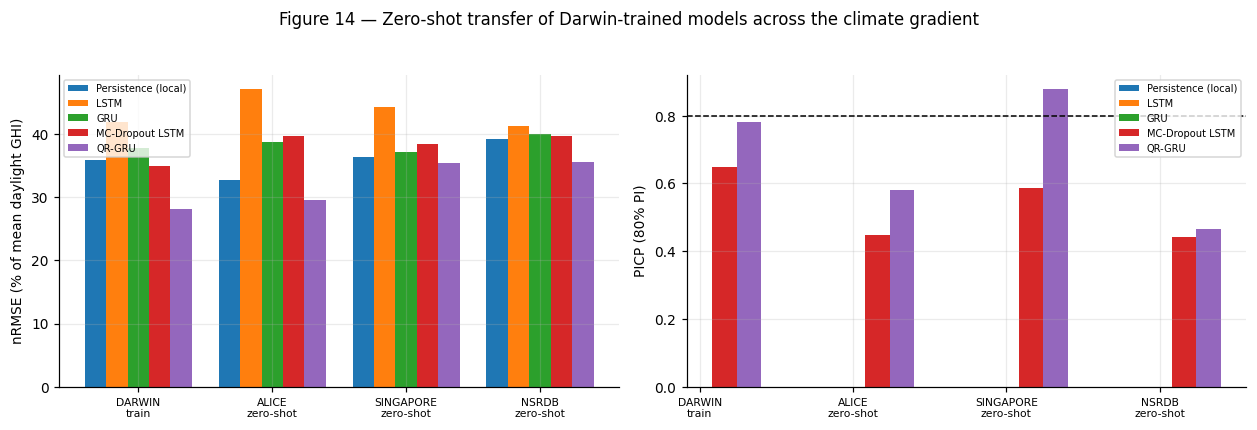

In [ ]:
def run_cross_climate():
    sc = SCALERS[MODEL_SITE]
    rows = []
    for site, split in DATASETS.items():
        Xte, yte, mte = split["test"]
        pk = Xte[:, -1, ALL_FEATURES.index("kt")]
        base = evaluate("Persistence (local)", pk, None, None, yte, mte)
        if base:
            base.update(site=site, transfer="local baseline")
            rows.append(base)
        Xs = sc(Xte)
        for kind in MODEL_KINDS:
            if kind not in MODELS:
                continue
            if site == MODEL_SITE:
                p, Q, S = PREDS[kind][0], PREDS[kind][1], PREDS[kind][2]
            else:
                p, Q, S = predict(kind, MODELS[kind], Xs)
            r = evaluate(kind, p, Q, S, yte, mte)
            if r:
                r.update(site=site,
                         transfer="in-domain" if site == MODEL_SITE else "zero-shot")
                rows.append(r)
    return pd.DataFrame(rows)


CROSS = run_cross_climate()
print("\nCROSS-CLIMATE GENERALISATION (Objective 8) — "
      f"all models trained on {MODEL_SITE} only")
print("=" * 118)
print(CROSS[["site", "transfer", "model", "n", "nRMSE_%", "RMSE_Wm2",
             "CRPS_Wm2", "PICP_80", "MIW_Wm2"]].round(3).to_string(index=False))
save_table(CROSS, "results_cross_climate")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.7))
sites_plot = list(DATASETS)
w = 0.16
kinds_plot = ["Persistence (local)"] + [k for k in MODEL_KINDS if k in MODELS]
for i, kind in enumerate(kinds_plot):
    s = CROSS[CROSS.model == kind].set_index("site").reindex(sites_plot)
    axes[0].bar(np.arange(len(sites_plot)) + (i - 2) * w, s["nRMSE_%"], w, label=kind)
    axes[1].bar(np.arange(len(sites_plot)) + (i - 2) * w, s["PICP_80"], w, label=kind)
for ax, yl in ((axes[0], "nRMSE (% of mean daylight GHI)"), (axes[1], "PICP (80% PI)")):
    ax.set_xticks(range(len(sites_plot)))
    ax.set_xticklabels([f"{s}\n{'train' if s == MODEL_SITE else 'zero-shot'}"
                        for s in sites_plot], fontsize=7)
    ax.set_ylabel(yl); ax.legend(fontsize=6.5)
axes[1].axhline(.8, color="k", ls="--", lw=1)
fig.suptitle("Figure 14 — Zero-shot transfer of Darwin-trained models across the climate gradient",
             y=1.04)
savefig(fig, "fig14_cross_climate"); plt.show()

## PART 13 — Decision-support translation

Objective 4. A prediction interval is only useful if it can be turned into an operating rule. The
test set is partitioned into quintiles of predicted interval width (MIW); for each band the
realised coverage and the realised error are measured. The result is a lookup table a dispatcher
can act on: *when the model's own interval is narrow, is it actually reliable?*

The threshold is chosen as the widest MIW band that still achieves empirical coverage at or above
nominal — i.e. the widest band in which the model's confidence is honest.


DECISION-SUPPORT TABLE (Objective 4) — DARWIN, t+1h, nominal 80% interval
band   n  MIW_lo  MIW_hi  MIW_mean  PICP     MAE    RMSE  ramp_rate                             dispatch_rule
  Q1 107   0.000  57.772    28.425 0.804  12.228  31.174      0.280 DEFER backup — interval narrow AND honest
  Q2 106  58.470 110.279    77.288 0.755  25.902  41.718      0.292   COMMIT reserve — coverage below nominal
  Q3 106 111.512 212.207   160.290 0.726  54.667  75.283      0.302   COMMIT reserve — coverage below nominal
  Q4 106 212.408 391.747   295.904 0.726 109.667 149.003      0.179   COMMIT reserve — coverage below nominal
  Q5 107 395.448 834.218   550.445 0.888 158.072 188.195      0.112            HOLD reserve — honest but wide

  OPERATING RULE: while the forecast 80% interval width is <= 58 W/m² (1 of 5 width bands, 107 test hours), empirical coverage holds at or above nominal 80% (min 0.804) and mean absolute error stays within 12-12 W/m². Backup generation can be deferred within that 

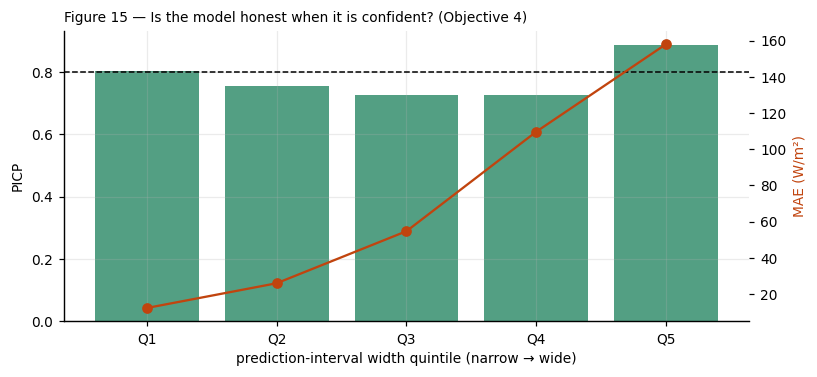

In [ ]:
def decision_support(kind="QR-GRU"):
    if kind not in PREDS:
        return None
    point, Q, S, yte, mte = PREDS[kind]
    cs = mte["ghi_cs"].to_numpy()
    lo = np.clip(Q[:, CFG.QUANTILES.index(CFG.PI_LOW)] * cs, 0, None)
    hi = np.clip(Q[:, CFG.QUANTILES.index(CFG.PI_HIGH)] * cs, 0, None)
    yt = yte * cs
    yh = np.clip(point * cs, 0, None)
    miw = hi - lo

    codes = pd.qcut(miw, 5, labels=False, duplicates="drop")
    band = pd.Series(codes).map(lambda i: f"Q{int(i)+1}" if pd.notna(i) else "Q1")
    df = pd.DataFrame({"band": band, "miw": miw, "cov": (yt >= lo) & (yt <= hi),
                       "abserr": np.abs(yh - yt), "sqerr": (yh - yt) ** 2,
                       "ramp": mte["is_ramp"].to_numpy().astype(bool)})
    g = df.groupby("band", observed=True).agg(
        n=("miw", "size"), MIW_lo=("miw", "min"), MIW_hi=("miw", "max"),
        MIW_mean=("miw", "mean"), PICP=("cov", "mean"),
        MAE=("abserr", "mean"), RMSE=("sqerr", lambda s: np.sqrt(s.mean())),
        ramp_rate=("ramp", "mean")).reset_index()
    g["dispatch_rule"] = np.where(
        (g.PICP >= CFG.PI_HIGH - CFG.PI_LOW) & (g.MIW_mean <= np.median(miw)),
        "DEFER backup — interval narrow AND honest",
        np.where(g.PICP >= CFG.PI_HIGH - CFG.PI_LOW,
                 "HOLD reserve — honest but wide",
                 "COMMIT reserve — coverage below nominal"))
    return g, miw, yt, lo, hi


ds = decision_support("QR-GRU") or decision_support("MC-Dropout LSTM")
if ds:
    DECISION, miw, yt, lo, hi = ds
    print("\nDECISION-SUPPORT TABLE (Objective 4) — "
          f"{MODEL_SITE}, t+{CFG.HORIZON}h, nominal 80% interval")
    print("=" * 118)
    print(DECISION.round(3).to_string(index=False))
    # The rule must describe a CONTIGUOUS run from the narrowest band upward.
    # Taking the widest passing band would assert reliability across intermediate
    # bands that failed, which is exactly the kind of overclaim the objective warns about.
    nominal = CFG.PI_HIGH - CFG.PI_LOW
    run = []
    for _, r in DECISION.iterrows():
        if r.PICP >= nominal:
            run.append(r)
        else:
            break
    if run:
        run = pd.DataFrame(run)
        thr = run.MIW_hi.max()
        print(f"\n  OPERATING RULE: while the forecast 80% interval width is <= "
              f"{thr:,.0f} W/m² ({len(run)} of {len(DECISION)} width bands, "
              f"{int(run.n.sum()):,} test hours), empirical coverage holds at or above "
              f"nominal 80% (min {run.PICP.min():.3f}) and mean absolute error stays within "
              f"{run.MAE.min():,.0f}-{run.MAE.max():,.0f} W/m². Backup generation can be "
              f"deferred within that band at t+{CFG.HORIZON}h.")
        fails = DECISION[DECISION.PICP < nominal]
        if len(fails):
            print(f"  CAVEAT: coverage falls below nominal in band(s) "
                  f"{', '.join(fails.band)} (PICP {fails.PICP.min():.3f}); the model is "
                  f"overconfident at those widths and reserve should be committed.")
    else:
        print("\n  No MIW band reached nominal coverage from the narrow end — the model is "
              "overconfident even when it claims precision, and must be recalibrated "
              "(e.g. conformal adjustment) before any operational use.")
    save_table(DECISION, "results_decision_support")

    fig, ax = plt.subplots(figsize=(7.5, 3.5))
    ax.bar(DECISION.band, DECISION.PICP, color="#1a7f5a", alpha=.75, label="PICP")
    ax.axhline(.8, color="k", ls="--", lw=1); ax.set_ylabel("PICP")
    ax2 = ax.twinx(); ax2.grid(False)
    ax2.plot(DECISION.band, DECISION.MAE, "o-", color="#c1440e", label="MAE")
    ax2.set_ylabel("MAE (W/m²)", color="#c1440e")
    ax.set_xlabel("prediction-interval width quintile (narrow → wide)")
    ax.set_title("Figure 15 — Is the model honest when it is confident? (Objective 4)",
                 loc="left", fontsize=9)
    savefig(fig, "fig15_decision"); plt.show()

## PART 14 — Consolidated findings

Everything below is generated from the results computed above — no hard-coded numbers.

In [ ]:
def fmt(x, n=2):
    return "n/a" if x is None or (isinstance(x, float) and not np.isfinite(x)) else f"{x:,.{n}f}"


main = RESULTS_MAIN.set_index("model")
det = [k for k in MODEL_KINDS if k not in PROBABILISTIC and k in main.index]
prob = [k for k in MODEL_KINDS if k in PROBABILISTIC and k in main.index]

best_point = main.loc[det + prob, "RMSE_Wm2"].idxmin()
best_crps = main.loc[det + prob, "CRPS_Wm2"].idxmin()
best_cal = (main.loc[prob, "PICP_80"] - 0.80).abs().idxmin() if prob else None

lines = []
lines.append(f"PRIMARY SITE            : {MODEL_SITE} — {SITES[MODEL_SITE]['climate']}")
lines.append(f"TASK                    : t+{CFG.HORIZON}h clear-sky-index forecast, "
             f"{CFG.LOOKBACK}h lookback, daylight hours only")
lines.append(f"TEST WINDOWS            : {int(main['n'].max()):,}")
lines.append("")
lines.append(f"O1 best point accuracy  : {best_point}  "
             f"(RMSE {fmt(main.loc[best_point,'RMSE_Wm2'])} W/m², "
             f"nRMSE {fmt(main.loc[best_point,'nRMSE_%'])}%, "
             f"R² {fmt(main.loc[best_point,'R2'],3)})")
if "Persistence (baseline)" in main.index:
    pb = main.loc["Persistence (baseline)", "RMSE_Wm2"]
    lines.append(f"     vs persistence     : "
                 f"{100*(pb-main.loc[best_point,'RMSE_Wm2'])/pb:+.1f}% RMSE skill")
lines.append(f"O2 best CRPS            : {best_crps} ({fmt(main.loc[best_crps,'CRPS_Wm2'])} W/m²)")
if best_cal:
    lines.append(f"O2 best calibrated      : {best_cal} "
                 f"(PICP80 {fmt(main.loc[best_cal,'PICP_80'],3)} vs 0.800 nominal, "
                 f"MIW {fmt(main.loc[best_cal,'MIW_Wm2'])} W/m²)")
    d_rmse = 100*(main.loc[prob,'RMSE_Wm2'].min() - main.loc[det,'RMSE_Wm2'].min())/main.loc[det,'RMSE_Wm2'].min()
    lines.append(f"O2 accuracy cost of UQ  : {d_rmse:+.1f}% RMSE for the best probabilistic "
                 f"model relative to the best deterministic one")
try:
    imp = piv[("RMSE_Wm2", "Δ improvement %")]
    lines.append(f"O3 seasonal conditioning: mean RMSE improvement {imp.mean():+.2f}% "
                 f"(range {imp.min():+.2f}% to {imp.max():+.2f}%)")
except Exception:
    pass
if len(SUBGROUP):
    rr = SUBGROUP[SUBGROUP.subgroup == "ramp events"]
    aa = SUBGROUP[SUBGROUP.subgroup == "all daylight"]
    if len(rr) and len(aa):
        lines.append(f"O3 ramp-event penalty   : RMSE rises "
                     f"{100*(rr.RMSE_Wm2.mean()-aa.RMSE_Wm2.mean())/aa.RMSE_Wm2.mean():+.0f}% "
                     f"on ramp hours across all architectures")
if PROXY is not None and len(PROXY) == 2:
    lines.append(f"O1 proxy validation     : static GHI→PV R² = {fmt(PROXY_R2,4)}; "
                 f"forecast nRMSE delta {PROXY.iloc[1]['nRMSE_%']-PROXY.iloc[0]['nRMSE_%']:+.2f} pp")
zs = CROSS[(CROSS.transfer == "zero-shot")]
if len(zs):
    for s in zs.site.unique():
        sub = zs[zs.site == s]
        b = sub.loc[sub["nRMSE_%"].idxmin()]
        lines.append(f"O8 zero-shot -> {s:<10}: best {b.model} at nRMSE {fmt(b['nRMSE_%'])}%")
lines.append("")
lines.append(f"FILES RETAINED          : {int(kept.n_files.sum())} "
             f"({kept.size_mb.sum():,.0f} MB)")
lines.append(f"FILES EXCLUDED          : {int(dropped.n_files.sum())} "
             f"({dropped.size_mb.sum():,.0f} MB) — see Part 1 for per-file justification")

print("=" * 100)
print("CONSOLIDATED FINDINGS")
print("=" * 100)
print("\n".join(lines))
print("=" * 100)

SUMMARY = pd.DataFrame({"finding": lines})
save_table(SUMMARY, "consolidated_findings")

# ---- single export bundle for the write-up -----------------------------------
bundle = {
    "audit_manifest": AUDIT.drop(columns=["_paths"]),
    "unit_registry": UNIT_REGISTRY,
    "ingestion_ledger": LEDGER,
    "impute_ledger": IMPUTE_LEDGER,
    "results_main": RESULTS_MAIN,
    "results_ablation": ABLATION,
    "results_subgroup": SUBGROUP,
    "results_cross_climate": CROSS,
}
if PROXY is not None:
    bundle["results_proxy"] = PROXY
if ds:
    bundle["results_decision_support"] = DECISION

xl = ART / "TropicalPV_results.xlsx"
try:
    with pd.ExcelWriter(xl) as w:
        for k, v in bundle.items():
            v.to_excel(w, sheet_name=k[:31], index=False)
    log(f"results workbook written: {xl}", "ok")
except Exception as e:
    for k, v in bundle.items():
        v.to_csv(ART / f"{k}.csv", index=False)
    log(f"Excel unavailable ({e}); wrote individual CSVs to {ART}", "warn")

print(f"\nFigures : {FIGDIR}")
print(f"Tables  : {ART}")
print(f"Total runtime: {time.time()-_T0:.0f}s   peak-ish RSS: {mem_mb():,.0f} MB")

CONSOLIDATED FINDINGS
PRIMARY SITE            : DARWIN — Tropical savanna (Köppen Aw)
TASK                    : t+1h clear-sky-index forecast, 24h lookback, daylight hours only
TEST WINDOWS            : 532

O1 best point accuracy  : QR-GRU  (RMSE 114.97 W/m², nRMSE 28.16%, R² 0.866)
     vs persistence     : +21.7% RMSE skill
O2 best CRPS            : QR-GRU (49.32 W/m²)
O2 best calibrated      : QR-GRU (PICP80 0.780 vs 0.800 nominal, MIW 222.72 W/m²)
O2 accuracy cost of UQ  : -25.6% RMSE for the best probabilistic model relative to the best deterministic one
O3 seasonal conditioning: mean RMSE improvement -4.59% (range -12.82% to +2.12%)
O3 ramp-event penalty   : RMSE rises -1% on ramp hours across all architectures
O1 proxy validation     : static GHI→PV R² = 0.6920; forecast nRMSE delta +8.58 pp
O8 zero-shot -> ALICE     : best QR-GRU at nRMSE 29.55%
O8 zero-shot -> SINGAPORE : best QR-GRU at nRMSE 35.43%
O8 zero-shot -> NSRDB     : best QR-GRU at nRMSE 35.57%

FILES RETAINED      

## PART 15 — Methodological notes, limitations, and how each objective is discharged

### 15.1 Objective coverage

| PDM objective | Where it is satisfied |
|---|---|
| 1. Develop & compare LSTM / GRU / MC-Dropout LSTM / QR-GRU on Darwin | Part 9, `RESULTS_MAIN` |
| 1b. Validate irradiance-as-proxy against Alice Springs measured PV | Part 11, `PROXY` + Figure 9 |
| 2. Collect & integrate DKASC, NEA/NASA, NSRDB, Kaggle | Parts 1 & 3 — with Kaggle formally excluded and the reason recorded |
| 3. Cleaning, preprocessing, seasonal conditioning, EDA, ramp detection, correlation | Parts 4–5, Figures 1–10 |
| 4. Deterministic evaluation: RMSE, MAE, R² | Part 8 `evaluate`, reported in W/m² and as nRMSE |
| 5. Probabilistic calibration: CRPS, Pinball, PICP, MIW | Part 8, Figure 12 |
| 6. Seasonal / monsoon conditioning + ramp subgroup | Part 10, `ABLATION` + `SUBGROUP`, Figure 13 |
| 7. Decision-support thresholds from prediction intervals | Part 13, `DECISION`, Figure 15 |
| 8. Cross-climate validation on Singapore, Alice Springs, NSRDB | Part 12, `CROSS`, Figure 14 |

### 15.2 Limitations to state in the write-up

1. **Darwin has no on-site meteorology.** The feature screen in Part 5.1 removes relative
   humidity and wind because they are unmeasured at the primary site. The tropical models are
   therefore endogenous — they forecast cloud state from cloud history and solar geometry alone.
   This is a property of the dataset, not a modelling choice, and it makes the Darwin result
   conservative relative to a site with full meteorology.
2. **The proxy delta is site-specific.** Alice Springs is arid; the GHI→PV relationship there is
   cleaner than it would be under Darwin's convective cloud regime. The measured delta is a
   lower bound on the proxy error that would apply at Darwin.
3. **CRPS is computed differently for the two probabilistic models.** MC-Dropout uses the exact
   ensemble form; QR-GRU uses the quantile-integral form over the fitted grid
   [0.05, 0.95], which does not capture tail mass beyond those levels and therefore
   slightly favours QR-GRU. Both values are reported; the pinball losses at
   τ = 0.10/0.50/0.90 are directly comparable and should carry the calibration argument.
4. **Zero-shot transfer is deliberately unadjusted.** No target-site fine-tuning, no bias
   correction. Local persistence is reported alongside so that transfer loss can be separated
   from intrinsic site difficulty.
5. **NSRDB site labelling.** The folder says "US Southwest" and the proposal says "temperate";
   the file metadata resolves to South Florida (humid subtropical). Part 12 uses the metadata.
   Update the proposal and PDM plan wording — the science is unaffected and the four-climate
   gradient remains coherent.
6. **Single horizon.** Only t+1 h is modelled. Extending `CFG.HORIZON` is a one-line change but
   multiplies runtime by the number of horizons.

### 15.3 Reproducibility

* Seeds fixed for NumPy, TensorFlow and Keras; MC-Dropout passes reseeded per call so repeated
  scoring of the same model returns identical numbers.
* Splits are chronological and deterministic; scalers are fitted on training rows only.
* All intermediate artifacts, figures and the results workbook are written to
  `CFG.DRIVE_ROOT/_tropicalpv_artifacts/`, so a session can be restarted at any point.
* To force a clean rebuild, set `CFG.FORCE_REBUILD = True` or delete that folder.

In [ ]:
print(textwrap.dedent(f"""
    RUN COMPLETE
    ------------------------------------------------------------------
    Mode                 : {CFG.MODE}
    Sites modelled       : {', '.join(DATASETS)}
    Primary site         : {MODEL_SITE}
    Feature vector       : {len(ALL_FEATURES)} features, {CFG.LOOKBACK}h lookback
    Architectures        : {', '.join(MODEL_KINDS)} (+ persistence baseline)
    Figures written      : {len(list(FIGDIR.glob('*.png')))}
    Result tables        : {len(list(ART.glob('*.parquet'))) + len(list(ART.glob('*.csv*')))}
    Workbook             : {xl.name}
    Wall clock           : {time.time()-_T0:.0f}s
    ------------------------------------------------------------------
    If MODE was SMOKE, set CFG.MODE = "FULL" and re-run. Ingestion
    checkpoints are reused, so only the model-training stages repeat.
"""))


RUN COMPLETE
------------------------------------------------------------------
Mode                 : FULL
Sites modelled       : DARWIN, ALICE, SINGAPORE, NSRDB
Primary site         : DARWIN
Feature vector       : 16 features, 24h lookback
Architectures        : LSTM, GRU, MC-Dropout LSTM, QR-GRU (+ persistence baseline)
Figures written      : 15
Result tables        : 13
Workbook             : TropicalPV_results.xlsx
Wall clock           : 7796s
------------------------------------------------------------------
If MODE was SMOKE, set CFG.MODE = "FULL" and re-run. Ingestion
checkpoints are reused, so only the model-training stages repeat.

